# Imports

In [1]:
from pesummary.io import read;

from pycbc.inference.io import loadfile;
from pycbc import conversions as cvs;
from pycbc import cosmology as cos;

import numpy as np
import matplotlib.pyplot as pp
import seaborn as sns

import pandas as pd

/home/chendawww/Software/anaconda3/envs/pycbc/lib/python3.12/site-packages/gwpy/time/__init__.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  from lal import LIGOTimeGPS


In [2]:
cos.redshift_from_comoving_volume(92918664351*25)

5.514401182877055

$N = - \frac{3}{128}\frac{1}{\eta}\pi^{-5/3}\\
$
\begin{aligned}
-\phi = Nf^{5/3}(\cdots + \phi_j f^{j/3} + \phi_{jl} f^{j/3}\log{f})
    = -f^{5/3}(\cdots + \psi_j f^{j/3} + \psi_{jl} f^{j/3}\log{f})\\
\end{aligned}

\begin{aligned}
-\phi^\prime = N((\cdots)^\prime + \left(\frac{j-8}{3}\phi_j + \phi_{jl}\right) f^{(j-8)/3} + \frac{j-8}{3}\phi_{jl} f^{(j-8)/3}\log{f})\\
    = (M)^{-8/3} \frac{5}{128 \pi^{5/3}}((\cdots)^\prime + \left(\frac{8-j}{5}\phi_j - \frac{3}{5}\phi_{jl}\right) f^{(j-8)/5} + \frac{8-j}{3}\phi_{jl} f^{(j-8)/3}\log{f})
    = \\
\end{aligned}

# Util Function

In [3]:
def augment_OGC_result(samples, approximant='SEOBNRv4PHM', f_ref=20) :
    # lalsuite里面只有SEOBNR的几个模型能算m_f, a_f
    samples = samples.add_fields(cvs.mass1_from_mchirp_q(samples['srcmchirp'], samples['q']), 'mass1')
    samples = samples.add_fields(cvs.mass2_from_mchirp_q(samples['srcmchirp'], samples['q']), 'mass2')
    samples = samples.add_fields(cvs.eta_from_mass1_mass2(samples['mass1'], samples['mass2']), 'eta')

    samples = samples.add_fields(cvs.mtotal_from_mass1_mass2(samples['mass1'], samples['mass2']), 'Mtot')
    samples = samples.add_fields(samples['srcmchirp'], 'Mchirp')
    # samples = samples.add_fields(cvs.eta_from_mass1_mass2(samples['mass1'], samples['mass2']), 'eta')
    samples = samples.add_fields(cvs.invq_from_mass1_mass2(samples['mass1'], samples['mass2']), 'invq')

    samples = samples.add_fields(cvs.chi_eff_from_spherical(samples['mass1'], samples['mass2'], samples['spin1_a'], samples['spin1_polar'], samples['spin2_a'], samples['spin2_polar']), 'chi_eff')
    samples = samples.add_fields(cvs.chi_p_from_spherical(samples['mass1'], samples['mass2'], samples['spin1_a'], samples['spin1_azimuthal'], samples['spin1_polar'], samples['spin2_a'],samples['spin1_azimuthal'], samples['spin2_polar']), 'chi_p')

    samples = samples.add_fields(cos.distance_from_comoving_volume(samples['comoving_volume']), 'distance')
    samples = samples.add_fields(cos.redshift_from_comoving_volume(samples['comoving_volume']), 'redshift')
    
    temp = {}
    temp['spin1_x'], temp['spin1_y'], temp['spin1_z'] = cvs._spherical_to_cartesian(samples['spin1_a'], samples['spin1_azimuthal'], samples['spin1_polar'])
    temp['spin2_x'], temp['spin2_y'], temp['spin2_z'] = cvs._spherical_to_cartesian(samples['spin2_a'], samples['spin2_azimuthal'], samples['spin2_polar'])

    samples = samples.add_fields(temp['spin1_x'], 'spin1_x')
    samples = samples.add_fields(temp['spin1_y'], 'spin1_y')
    samples = samples.add_fields(temp['spin1_z'], 'spin1_z')
    samples = samples.add_fields(temp['spin2_x'], 'spin2_x')
    samples = samples.add_fields(temp['spin2_y'], 'spin2_y')
    samples = samples.add_fields(temp['spin2_z'], 'spin2_z')


    # 这两个算得很慢
    # samples = samples.add_fields(cvs.final_mass_from_initial(samples['mass1'], samples['mass2'], samples['spin1_x'], samples['spin1_y'], samples['spin1_z'], samples['spin2_x'], samples['spin2_y'], samples['spin2_z'], approximant=approximant, f_ref=f_ref), 'm_f')
    # samples = samples.add_fields(cvs.final_spin_from_initial(samples['mass1'], samples['mass2'], samples['spin1_x'], samples['spin1_y'], samples['spin1_z'], samples['spin2_x'], samples['spin2_y'], samples['spin2_z'], approximant=approximant, f_ref=f_ref), 'a_f')

    return samples

In [4]:
def augment_OGC_XAS_result(samples, approximant='SEOBNRv4PHM', f_ref=20) :
    # lalsuite里面只有SEOBNR的几个模型能算m_f, a_f
    samples = samples.add_fields(cvs.mass1_from_mchirp_q(samples['srcmchirp'], samples['q']), 'mass1')
    samples = samples.add_fields(cvs.mass2_from_mchirp_q(samples['srcmchirp'], samples['q']), 'mass2')
    samples = samples.add_fields(cvs.eta_from_mass1_mass2(samples['mass1'], samples['mass2']), 'eta')

    samples = samples.add_fields(cvs.mtotal_from_mass1_mass2(samples['mass1'], samples['mass2']), 'Mtot')
    samples = samples.add_fields(samples['srcmchirp'], 'Mchirp')
    # samples = samples.add_fields(cvs.eta_from_mass1_mass2(samples['mass1'], samples['mass2']), 'eta')
    samples = samples.add_fields(cvs.invq_from_mass1_mass2(samples['mass1'], samples['mass2']), 'invq')

    # samples = samples.add_fields(cvs.chi_eff_from_spherical(samples['mass1'], samples['mass2'], samples['spin1_a'], samples['spin1_polar'], samples['spin2_a'], samples['spin2_polar']), 'chi_eff')
    # samples = samples.add_fields(cvs.chi_p_from_spherical(samples['mass1'], samples['mass2'], samples['spin1_a'], samples['spin1_azimuthal'], samples['spin1_polar'], samples['spin2_a'],samples['spin1_azimuthal'], samples['spin2_polar']), 'chi_p')

    samples = samples.add_fields(cos.distance_from_comoving_volume(samples['comoving_volume']), 'distance')
    samples = samples.add_fields(cos.redshift_from_comoving_volume(samples['comoving_volume']), 'redshift')
    
    temp = {}
    # temp['spin1_x'], temp['spin1_y'], temp['spin1_z'] = cvs._spherical_to_cartesian(samples['spin1_a'], samples['spin1_azimuthal'], samples['spin1_polar'])
    # temp['spin2_x'], temp['spin2_y'], temp['spin2_z'] = cvs._spherical_to_cartesian(samples['spin2_a'], samples['spin2_azimuthal'], samples['spin2_polar'])

    # samples = samples.add_fields(temp['spin1_x'], 'spin1_x')
    # samples = samples.add_fields(temp['spin1_y'], 'spin1_y')
    # samples = samples.add_fields(samples['spin1z'], 'spin1z')
    # samples = samples.add_fields(temp['spin2_x'], 'spin2_x')
    # samples = samples.add_fields(temp['spin2_y'], 'spin2_y')
    # samples = samples.add_fields(samples['spin2z'], 'spin2z')


    # 这两个算得很慢
    # samples = samples.add_fields(cvs.final_mass_from_initial(samples['mass1'], samples['mass2'], samples['spin1_x'], samples['spin1_y'], samples['spin1_z'], samples['spin2_x'], samples['spin2_y'], samples['spin2_z'], approximant=approximant, f_ref=f_ref), 'm_f')
    # samples = samples.add_fields(cvs.final_spin_from_initial(samples['mass1'], samples['mass2'], samples['spin1_x'], samples['spin1_y'], samples['spin1_z'], samples['spin2_x'], samples['spin2_y'], samples['spin2_z'], approximant=approximant, f_ref=f_ref), 'a_f')

    return samples

# Data Reading and Pre-processing

## OGC Posteriors

In [5]:
posteriors_path = "/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors"

samples = {}
samples['GW150914'] = {}

samples['GW150914_095045'] = {}
samples['GW151012'] = {}
samples['GW170104'] = {}
samples['GW170608'] = {}
samples['GW170729'] = {}
samples['GW170809'] = {}
samples['GW170818'] = {}
samples['GW170823'] = {}

samples['GW151226'] = {}
samples['GW170814'] = {}


samples['GW200129_065458'] = {}


In [19]:
# # 自己，OGC-4官方
# fp = loadfile('OGC4-GW150914.hdf', 'r')
# samples0 = fp.read_samples(fp['samples'].keys())

# # OGC-4官方
# fp = loadfile('GW150914_095045-PYCBC-POSTERIOR-IMRPhenomXPHM.hdf', 'r')
# samples1 = fp.read_samples(fp['samples'].keys())

# # OGC-3官方
# fp = loadfile('GW150914_095045-PYCBC-POSTERIOR-XPHM.hdf', 'r')
# samples2 = fp.read_samples(fp['samples'].keys())

# # 自己，OGC-4官方，no calibration
# fp = loadfile('GW150914_095045-PYCBC-POSTERIOR-XPHM.hdf', 'r')
# samples3 = fp.read_samples(fp['samples'].keys())


In [43]:

# results.append(dict(
#     event_name='GW150914',
#     deviation_name='GR',
#     result_posterior_path='OGC/GW150914',
#     posterior_file_name='OGC4-GW150914.hdf',
#     label="GW150914, GR"
# ))

# results.append(dict(
#     event_name='GW150914',
#     deviation_name='fdchi3',
#     result_posterior_path='OGC/GW150914',
#     posterior_file_name='OGC4-GW150914_fdchi3.hdf',
#     label="GW150914, fdchi3"
# ))

# results.append(dict(
#     event_name='GW150914',
#     deviation_name='cpsi3',
#     result_posterior_path='OGC/GW150914',
#     posterior_file_name='OGC4-GW150914_cpsi3.hdf',
#     label="GW150914, cpsi3"
# ))

# results.append(dict(
#     event_name='GW150914',
#     deviation_name='fdchi4',
#     result_posterior_path='OGC/GW150914',
#     posterior_file_name='OGC4-GW150914_fdchi4.hdf',
#     label="GW150914, fdchi4"
# ))

# results.append(dict(
#     event_name='GW150914',
#     deviation_name='cpsi4',
#     result_posterior_path='OGC/GW150914',
#     posterior_file_name='OGC4-GW150914_cpsi4.hdf',
#     label="GW150914, cpsi4"
# ))

# results.append(dict(
#     event_name='GW150914',
#     deviation_name='fdchi5l',
#     result_posterior_path='OGC/GW150914',
#     posterior_file_name='OGC4-GW150914_fdchi5l.hdf',
#     label="GW150914, fdchi5l"
# ))

# results.append(dict(
#     event_name='GW150914',
#     deviation_name='cpsi5l',
#     result_posterior_path='OGC/GW150914',
#     posterior_file_name='OGC4-GW150914_cpsi5l.hdf',
#     label="GW150914, cdchi5l"
# ))

# results.append(dict(
#     event_name='GW150914',
#     deviation_name='fdchi6l',
#     result_posterior_path='OGC/GW150914',
#     posterior_file_name='OGC4-GW150914_fdchi6l.hdf',
#     label="GW150914, fdchi6l"
# ))

# results.append(dict(
#     event_name='GW150914',
#     deviation_name='cpsi6l',
#     result_posterior_path='OGC/GW150914',
#     posterior_file_name='OGC4-GW150914_cpsi6l.hdf',
#     label="GW150914, cdchi6l"
# ))

In [44]:

# results.append(dict(
#     event_name='GW150914',
#     deviation_name='GR',
#     result_posterior_path='OGC/GW150914',
#     posterior_file_name='OGC4-GW150914.hdf',
#     label="GW150914, GR"
# ))

# results.append(dict(
#     event_name='GW150914',
#     deviation_name='cpsi3',
#     result_posterior_path='OGC/GW150914',
#     posterior_file_name='OGC4-GW150914_cpsi3.hdf',
#     label="GW150914, cpsi3"
# ))

# results.append(dict(
#     event_name='GW150914',
#     deviation_name='dchi3',
#     result_posterior_path='OGC/GW150914',
#     posterior_file_name='OGC4-GW150914_dchi3.hdf',
#     label="GW150914, dchi3"
# ))

In [16]:
results = []

In [65]:
# results.append(dict(
#     event_name='GW200129_065458',
#     deviation_name='GR',
#     result_posterior_path='OGC/GW200129_065458',
#     posterior_file_name='OGC4-GW200129_065458_GR.hdf',
#     label="GW200129_065458, GR"
# ))

# results.append(dict(
#     event_name='GW200129_065458',
#     deviation_name='cpsi4',
#     result_posterior_path='OGC/GW200129_065458',
#     posterior_file_name='OGC4-GW200129_065458_cpsi4.hdf',
#     label="GW200129_065458, cpsi4"
# ))


# results.append(dict(
#     event_name='GW150914_095045',
#     deviation_name='cpsi1',
#     result_posterior_path='OGC/GW150914_095045',
#     posterior_file_name='GW150914_095045_cpsi1.hdf',
#     label="GW150914_095045, cpsi1"
# ))

# results.append(dict(
#     event_name='GW150914_095045',
#     deviation_name='cpsi2',
#     result_posterior_path='OGC/GW150914_095045',
#     posterior_file_name='GW150914_095045_cpsi2.hdf',
#     label="GW150914_095045, cpsi2"
# ))

results.append(dict(
    event_name='GW150914_095045',
    deviation_name='gr',
    result_posterior_path='OGC/GW150914_095045',
    posterior_file_name='GW150914_095045_gr.hdf',
    label="GW150914_095045, gr"
))

results.append(dict(
    event_name='GW150914_095045',
    deviation_name='cpsi0',
    result_posterior_path='OGC/GW150914_095045',
    posterior_file_name='GW150914_095045_cpsi0.hdf',
    label="GW150914_095045, cpsi0"
))

results.append(dict(
    event_name='GW150914_095045',
    deviation_name='cpsi1',
    result_posterior_path='OGC/GW150914_095045',
    posterior_file_name='GW150914_095045_cpsi1.hdf',
    label="GW150914_095045, cpsi1"
))

results.append(dict(
    event_name='GW150914_095045',
    deviation_name='cpsi2',
    result_posterior_path='OGC/GW150914_095045',
    posterior_file_name='GW150914_095045_cpsi2.hdf',
    label="GW150914_095045, cpsi2"
))

results.append(dict(
    event_name='GW150914_095045',
    deviation_name='cpsi3',
    result_posterior_path='OGC/GW150914_095045',
    posterior_file_name='GW150914_095045_cpsi3.hdf',
    label="GW150914_095045, cpsi3"
))

results.append(dict(
    event_name='GW150914_095045',
    deviation_name='dchi3',
    result_posterior_path='OGC/GW150914_095045',
    posterior_file_name='GW150914_095045_dchi3.hdf',
    label="GW150914_095045, dchi3"
))

results.append(dict(
    event_name='GW150914_095045',
    deviation_name='cpsi4',
    result_posterior_path='OGC/GW150914_095045',
    posterior_file_name='GW150914_095045_cpsi4.hdf',
    label="GW150914_095045, cpsi4"
))

results.append(dict(
    event_name='GW150914_095045',
    deviation_name='cpsi5l',
    result_posterior_path='OGC/GW150914_095045',
    posterior_file_name='GW150914_095045_cpsi5l.hdf',
    label="GW150914_095045, cpsi5l"
))

results.append(dict(
    event_name='GW150914_095045',
    deviation_name='cpsi6',
    result_posterior_path='OGC/GW150914_095045',
    posterior_file_name='GW150914_095045_cpsi6.hdf',
    label="GW150914_095045, cpsi6"
))

results.append(dict(
    event_name='GW150914_095045',
    deviation_name='cpsi6l',
    result_posterior_path='OGC/GW150914_095045',
    posterior_file_name='GW150914_095045_cpsi6l.hdf',
    label="GW150914_095045, cpsi6l"
))


In [46]:
results = []

In [47]:

# results.append(dict(
#     event_name='GW151012',
#     deviation_name='gr',
#     result_posterior_path='OGC/GW150914_095045',
#     posterior_file_name='GW150914_095045_gr.hdf',
#     label="GW151012, gr"
# ))

results.append(dict(
    event_name='GW151012',
    deviation_name='cpsi0',
    result_posterior_path='OGC/GW151012',
    posterior_file_name='GW151012_cpsi0.hdf',
    label="GW151012, cpsi0"
))

# results.append(dict(
#     event_name='GW150914_095045',
#     deviation_name='cpsi1',
#     result_posterior_path='OGC/GW150914_095045',
#     posterior_file_name='GW150914_095045_cpsi1.hdf',
#     label="GW150914_095045, cpsi1"
# ))

# results.append(dict(
#     event_name='GW150914_095045',
#     deviation_name='cpsi2',
#     result_posterior_path='OGC/GW150914_095045',
#     posterior_file_name='GW150914_095045_cpsi2.hdf',
#     label="GW150914_095045, cpsi2"
# ))

# results.append(dict(
#     event_name='GW150914_095045',
#     deviation_name='cpsi3',
#     result_posterior_path='OGC/GW150914_095045',
#     posterior_file_name='GW150914_095045_cpsi3.hdf',
#     label="GW150914_095045, cpsi3"
# ))

# results.append(dict(
#     event_name='GW150914_095045',
#     deviation_name='dchi3',
#     result_posterior_path='OGC/GW150914_095045',
#     posterior_file_name='GW150914_095045_dchi3.hdf',
#     label="GW150914_095045, dchi3"
# ))

# results.append(dict(
#     event_name='GW150914_095045',
#     deviation_name='cpsi4',
#     result_posterior_path='OGC/GW150914_095045',
#     posterior_file_name='GW150914_095045_cpsi4.hdf',
#     label="GW150914_095045, cpsi4"
# ))

# results.append(dict(
#     event_name='GW150914_095045',
#     deviation_name='cpsi5l',
#     result_posterior_path='OGC/GW150914_095045',
#     posterior_file_name='GW150914_095045_cpsi5l.hdf',
#     label="GW150914_095045, cpsi5l"
# ))

# results.append(dict(
#     event_name='GW150914_095045',
#     deviation_name='cpsi6',
#     result_posterior_path='OGC/GW150914_095045',
#     posterior_file_name='GW150914_095045_cpsi6.hdf',
#     label="GW150914_095045, cpsi6"
# ))

# results.append(dict(
#     event_name='GW150914_095045',
#     deviation_name='cpsi6l',
#     result_posterior_path='OGC/GW150914_095045',
#     posterior_file_name='GW150914_095045_cpsi6l.hdf',
#     label="GW150914_095045, cpsi6l"
# ))

In [85]:
results = []

In [86]:
results.append(dict(
    event_name='GW151012',
    deviation_name='cpsi0',
    result_posterior_path='OGC/GW151012',
    posterior_file_name='GW151012_cpsi0.hdf',
    label="GW151012, cpsi0"
))

results.append(dict(
    event_name='GW151012',
    deviation_name='cpsi2',
    result_posterior_path='OGC/GW151012',
    posterior_file_name='GW151012_cpsi2.hdf',
    label="GW151012, cpsi2"
))

In [125]:
results = []

In [126]:
results.append(dict(
    event_name='GW151226',
    deviation_name='cpsi0',
    result_posterior_path='OGC/GW151226',
    posterior_file_name='GW151226_cpsi0.hdf',
    label="GW151226, cpsi0"
))
results.append(dict(
    event_name='GW151226',
    deviation_name='cpsi2',
    result_posterior_path='OGC/GW151226',
    posterior_file_name='GW151226_cpsi2.hdf',
    label="GW151226, cpsi2"
))
results.append(dict(
    event_name='GW151226',
    deviation_name='cpsi3',
    result_posterior_path='OGC/GW151226',
    posterior_file_name='GW151226_cpsi3.hdf',
    label="GW151226, cpsi3"
))

In [41]:
results = []

In [42]:
results.append(dict(
    event_name='GW170104',
    deviation_name='cpsi0',
    result_posterior_path='OGC/GW170104',
    posterior_file_name='GW170104_cpsi0.hdf',
    label="GW170104, cpsi0"
))

results.append(dict(
    event_name='GW170104',
    deviation_name='cpsi2',
    result_posterior_path='OGC/GW170104',
    posterior_file_name='GW170104_cpsi2.hdf',
    label="GW170104, cpsi2"
))

results.append(dict(
    event_name='GW170104',
    deviation_name='cpsi3',
    result_posterior_path='OGC/GW170104',
    posterior_file_name='GW170104_cpsi3.hdf',
    label="GW170104, cpsi3"
))

results.append(dict(
    event_name='GW170104',
    deviation_name='cpsi4',
    result_posterior_path='OGC/GW170104',
    posterior_file_name='GW170104_cpsi4.hdf',
    label="GW170104, cpsi4"
))

results.append(dict(
    event_name='GW170104',
    deviation_name='cpsi5l',
    result_posterior_path='OGC/GW170104',
    posterior_file_name='GW170104_cpsi5l.hdf',
    label="GW170104, cpsi5l"
))

results.append(dict(
    event_name='GW170104',
    deviation_name='cpsi6',
    result_posterior_path='OGC/GW170104',
    posterior_file_name='GW170104_cpsi6.hdf',
    label="GW170104, cpsi6"
))

results.append(dict(
    event_name='GW170104',
    deviation_name='cpsi6l',
    result_posterior_path='OGC/GW170104',
    posterior_file_name='GW170104_cpsi6l.hdf',
    label="GW170104, cpsi6l"
))

In [112]:
results = []

In [113]:
results.append(dict(
    event_name='GW170608',
    deviation_name='cpsi0',
    result_posterior_path='OGC/GW170608',
    posterior_file_name='GW170608_cpsi0.hdf',
    label="GW170608, cpsi0"
))
results.append(dict(
    event_name='GW170608',
    deviation_name='cpsi2',
    result_posterior_path='OGC/GW170608',
    posterior_file_name='GW170608_cpsi2.hdf',
    label="GW170608, cpsi2"
))
results.append(dict(
    event_name='GW170608',
    deviation_name='cpsi3',
    result_posterior_path='OGC/GW170608',
    posterior_file_name='GW170608_cpsi3.hdf',
    label="GW170608, cpsi3"
))
results.append(dict(
    event_name='GW170608',
    deviation_name='cpsi4',
    result_posterior_path='OGC/GW170608',
    posterior_file_name='GW170608_cpsi4.hdf',
    label="GW170608, cpsi4"
))

In [132]:
results = []

In [133]:
results.append(dict(
    event_name='GW170809',
    deviation_name='cpsi0',
    result_posterior_path='OGC/GW170809',
    posterior_file_name='GW170809_cpsi0.hdf',
    label="GW170809, cpsi0"
))
results.append(dict(
    event_name='GW170809',
    deviation_name='cpsi2',
    result_posterior_path='OGC/GW170809',
    posterior_file_name='GW170809_cpsi2.hdf',
    label="GW170809, cpsi2"
))
results.append(dict(
    event_name='GW170809',
    deviation_name='cpsi3',
    result_posterior_path='OGC/GW170809',
    posterior_file_name='GW170809_cpsi3.hdf',
    label="GW170809, cpsi3"
))
results.append(dict(
    event_name='GW170809',
    deviation_name='cpsi4',
    result_posterior_path='OGC/GW170809',
    posterior_file_name='GW170809_cpsi4.hdf',
    label="GW170809, cpsi4"
))
results.append(dict(
    event_name='GW170809',
    deviation_name='cpsi5l',
    result_posterior_path='OGC/GW170809',
    posterior_file_name='GW170809_cpsi5l.hdf',
    label="GW170809, cpsi5l"
))
results.append(dict(
    event_name='GW170809',
    deviation_name='cpsi6',
    result_posterior_path='OGC/GW170809',
    posterior_file_name='GW170809_cpsi6.hdf',
    label="GW170809, cpsi6"
))
results.append(dict(
    event_name='GW170809',
    deviation_name='cpsi6l',
    result_posterior_path='OGC/GW170809',
    posterior_file_name='GW170809_cpsi6l.hdf',
    label="GW170809, cpsi6l"
))

In [67]:
results.append(dict(
    event_name='GW170818',
    deviation_name='cpsi0',
    result_posterior_path='OGC/GW170818',
    posterior_file_name='GW170818_cpsi0.hdf',
    label="GW170818, cpsi0"
))

In [65]:
results = []

In [66]:
results.append(dict(
    event_name='GW170729',
    deviation_name='cpsi0',
    result_posterior_path='OGC/GW170729',
    posterior_file_name='GW170729_cpsi0.hdf',
    label="GW170729, cpsi0"
))

In [121]:
results = []

In [134]:
results.append(dict(
    event_name='GW170814',
    deviation_name='cpsi0',
    result_posterior_path='OGC/GW170814',
    posterior_file_name='GW170814_cpsi0.hdf',
    label="GW170814, cpsi0"
))
results.append(dict(
    event_name='GW170814',
    deviation_name='cpsi2',
    result_posterior_path='OGC/GW170814',
    posterior_file_name='GW170814_cpsi2.hdf',
    label="GW170814, cpsi2"
))
results.append(dict(
    event_name='GW170814',
    deviation_name='cpsi3',
    result_posterior_path='OGC/GW170814',
    posterior_file_name='GW170814_cpsi3.hdf',
    label="GW170814, cpsi3"
))
results.append(dict(
    event_name='GW170814',
    deviation_name='cpsi4',
    result_posterior_path='OGC/GW170814',
    posterior_file_name='GW170814_cpsi4.hdf',
    label="GW170814, cpsi4"
))
results.append(dict(
    event_name='GW170814',
    deviation_name='cpsi5l',
    result_posterior_path='OGC/GW170814',
    posterior_file_name='GW170814_cpsi5l.hdf',
    label="GW170814, cpsi5l"
))
results.append(dict(
    event_name='GW170814',
    deviation_name='cpsi6',
    result_posterior_path='OGC/GW170814',
    posterior_file_name='GW170814_cpsi6.hdf',
    label="GW170814, cpsi6"
))
results.append(dict(
    event_name='GW170814',
    deviation_name='cpsi6l',
    result_posterior_path='OGC/GW170814',
    posterior_file_name='GW170814_cpsi6l.hdf',
    label="GW170814, cpsi6l"
))

In [54]:
results = []

In [55]:
results.append(dict(
    event_name='GW170823',
    deviation_name='cpsi0',
    result_posterior_path='OGC/GW170823',
    posterior_file_name='GW170823_cpsi0.hdf',
    label="GW170823, cpsi0"
))

In [32]:
# for result in results:
#     fp = loadfile(posteriors_path + '/' + result['result_posterior_path'] + '/' + result['posterior_file_name'], 'r')
#     samples[result['event_name']][result['deviation_name']] = fp.read_samples(fp['samples'].keys())
#     samples[result['event_name']][result['deviation_name']] = augment_OGC_result(samples[result['event_name']][result['deviation_name']])
#     samples[result['event_name']][result['deviation_name']] = pd.DataFrame(samples[result['event_name']][result['deviation_name']])
#     samples[result['event_name']][result['deviation_name']].attrs['label'] = result['label']

In [136]:
for result in results:
    print(posteriors_path + '/' + result['result_posterior_path'] + '/' + result['posterior_file_name'])
    fp = loadfile(posteriors_path + '/' + result['result_posterior_path'] + '/' + result['posterior_file_name'], 'r')
    samples[result['event_name']][result['deviation_name']] = fp.read_samples(fp['samples'].keys())
    samples[result['event_name']][result['deviation_name']] = augment_OGC_XAS_result(samples[result['event_name']][result['deviation_name']])
    samples[result['event_name']][result['deviation_name']] = pd.DataFrame(samples[result['event_name']][result['deviation_name']])
    samples[result['event_name']][result['deviation_name']].attrs['label'] = result['label']

/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW170809/GW170809_cpsi0.hdf
/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW170809/GW170809_cpsi2.hdf
/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW170809/GW170809_cpsi3.hdf
/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW170809/GW170809_cpsi4.hdf
/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW170809/GW170809_cpsi5l.hdf
/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW170809/GW170809_cpsi6.hdf
/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW170809/GW170809_cpsi6l.hdf
/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW170814/GW170814_cpsi0.hdf
/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW170814/GW170814_cpsi2.hdf
/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW170814/GW170814_cpsi3.hdf
/mnt/d/Documents/workspace/课题/workspac

In [ ]:
csv_path = "/mnt/d/Documents/workspace/课题/workspace/Local/Parameterized_PN_Tests/csv"
# 挑选参数输出为csv，以方便Mathematica操作

# samples["fdchi3"][["mass1","mass2","spin1_z","spin2_z","eta","Mchirp","dchi3"]].to_csv(csv_path+'/OGC4-GW150914_fdchi3.csv', index=False)
# samples["fdchi4"][["mass1","mass2","spin1_z","spin2_z","eta","Mchirp","dchi4"]].to_csv(csv_path+'/OGC4-GW150914_fdchi4.csv', index=False)
# samples["fdchi5l"][["mass1","mass2","spin1_z","spin2_z","eta","Mchirp","dchi5l"]].to_csv(csv_path+'/OGC4-GW150914_fdchi5l.csv', index=False)
# samples["fdchi6l"][["mass1","mass2","spin1_z","spin2_z","eta","Mchirp","dchi6l"]].to_csv(csv_path+'/OGC4-GW150914_fdchi6l.csv', index=False)
# samples['GW150914']['cpsi3_debuged_m1500'][["mass1","mass2","spin1_z","spin2_z","eta","Mchirp","dchi3"]].to_csv(csv_path+'/GW150914/OGC4-GW150914_cpsi3_debuged_m1500.csv', index=False)
# samples['GW150914']['cpsi3'][["mass1","mass2","spin1_z","spin2_z","eta","Mchirp","dchi3"]].to_csv(csv_path+'/GW150914/OGC4-GW150914_cpsi3.csv', index=False)
# samples['GW150914']['cpsi4'][["mass1","mass2","spin1_z","spin2_z","eta","Mchirp","dchi4"]].to_csv(csv_path+'/GW150914/OGC4-GW150914_cpsi4.csv', index=False)
# samples['GW150914']['cpsi5l'][["mass1","mass2","spin1_z","spin2_z","eta","Mchirp","dchi5l"]].to_csv(csv_path+'/GW150914/OGC4-GW150914_cpsi5l.csv', index=False)
# samples['GW150914']['cpsi6l'][["mass1","mass2","spin1_z","spin2_z","eta","Mchirp","dchi6l"]].to_csv(csv_path+'/GW150914/OGC4-GW150914_cpsi6l.csv', index=False)

# samples['GW200129_065458']['cpsi4'][["mass1","mass2","spin1_z","spin2_z","eta","Mchirp","dchi4"]].to_csv(csv_path+'/GW200129_065458/GW200129_065458_cpsi4.csv', index=False)

In [75]:
csv_path = "/mnt/d/Documents/workspace/课题/workspace/Local/Parameterized_PN_Tests/csv"

cpsijs = ['cpsi0', 'cpsi1', 'cpsi2', 'cpsi3', 'cpsi4', 'cpsi5l', 'cpsi6', 'cpsi6l']
dchijs = ['dchi0', 'dchi1', 'dchi2', 'dchi3', 'dchi4', 'dchi5l', 'dchi6', 'dchi6l']

for j, cpsij in enumerate(cpsijs) :
    samples['GW150914_095045'][cpsij][["mass1","mass2","spin1z","spin2z","eta","Mchirp",dchijs[j]]].to_csv(csv_path+'/GW150914_095045/GW150914_095045_' + cpsij + '.csv', index=False)

In [72]:
samples['GW150914_095045']['gr'].keys()

Index(['loglikelihood', 'recalib_amplitude_h1_2', 'delta_tc',
       'recalib_amplitude_h1_1', 'recalib_amplitude_h1_4',
       'recalib_amplitude_h1_9', 'recalib_amplitude_l1_3',
       'recalib_phase_l1_4', 'recalib_phase_h1_4', 'recalib_phase_l1_1',
       'recalib_amplitude_l1_7', 'recalib_phase_l1_0', 'ra', 'comoving_volume',
       'recalib_phase_h1_2', 'dec', 'recalib_phase_l1_9', 'recalib_phase_h1_9',
       'recalib_amplitude_h1_8', 'recalib_amplitude_h1_6',
       'recalib_phase_l1_2', 'inclination', 'recalib_phase_l1_7',
       'recalib_phase_l1_3', 'recalib_phase_h1_5', 'recalib_amplitude_l1_8',
       'recalib_amplitude_h1_7', 'coa_phase', 'recalib_phase_l1_5',
       'recalib_amplitude_l1_2', 'srcmchirp', 'recalib_phase_h1_0', 'spin1z',
       'recalib_amplitude_l1_6', 'recalib_amplitude_l1_4',
       'recalib_phase_l1_8', 'recalib_amplitude_h1_5', 'q',
       'recalib_phase_h1_3', 'logwt', 'recalib_amplitude_l1_9',
       'recalib_amplitude_l1_1', 'recalib_phase_h1_1',
 

In [35]:
samples

{'GW150914': {}, 'GW150914_095045': {}, 'GW170817': {}, 'GW200129_065458': {}}

# Visualisation

In [9]:
import corner

quantiles = [0.05, 0.50, 0.95]

In [10]:
def plot_parameter(samples: pd.DataFrame, parameter_name, label, type='plot', bins=100, boundary_color='black', quantiles=[0.10, 0.50, 0.90], vlines_colors='blue', if_plot_vlines=False) :
    p = pd.cut(samples[parameter_name], bins=bins).value_counts(sort=False) / len(samples[parameter_name])
    x = pd.cut(samples[parameter_name], bins=bins).cat.categories.left.tolist()
    if type=='plot' :
        pp.plot(x, p, color=boundary_color, label=label)
    if type=='step' :
        pp.step(x, p, color=boundary_color, label=label)
    if type=='violin' :
        sns.violinplot(x=x, y=p)
    if if_plot_vlines:
        pp.vlines(samples[parameter_name].quantile(quantiles).values,
            ymin=0.0, ymax=max(p),
            linestyles = "dashed",
            colors=vlines_colors)

In [11]:
def get_label_str(samples, parameter_name, parameter_latex, quantiles=[0.10, 0.50, 0.90]) :
    label = samples.attrs['label']
    BCI = samples[parameter_name].quantile(quantiles).values
    left = np.round(BCI[1] - BCI[0], 3)
    median = np.round(BCI[1], 3)
    right= np.round(BCI[2] - BCI[1], 3)

    label += '; '
    label += parameter_latex
    label += ' = '
    label += f'${median}_{{-{left} }}^{{+{right} }}$'
    return label

In [ ]:

# par_list = ['mass1', 'mass2', 'chi_eff', 'chi_p', 'dchi3']
# corner.corner(samples['GW150914']['cpsi3'][par_list], labels=par_list);

# par_list = ['mass1', 'mass2', 'chi_eff', 'chi_p', 'dchi3']
# corner.corner(samples['GW150914']['fdchi3'][par_list], labels=par_list);

# par_list = ['mass1', 'mass2', 'chi_eff', 'chi_p', 'dchi4']
# corner.corner(samples['GW150914']['cpsi4'][par_list], labels=par_list);

# par_list = ['mass1', 'mass2', 'chi_eff', 'chi_p', 'dchi4']
# corner.corner(samples['GW150914']['fdchi4'][par_list], labels=par_list);

# par_list = ['mass1', 'mass2', 'chi_eff', 'chi_p', 'dchi5l']
# corner.corner(samples['GW150914']['cpsi5l'][par_list], labels=par_list);

# par_list = ['mass1', 'mass2', 'chi_eff', 'chi_p', 'dchi5l']
# corner.corner(samples['GW150914']['fdchi5l'][par_list], labels=par_list);

# par_list = ['mass1', 'mass2', 'chi_eff', 'chi_p', 'dchi6l']
# corner.corner(samples['GW150914']['cpsi6l'][par_list], labels=par_list);

# par_list = ['mass1', 'mass2', 'chi_eff', 'chi_p', 'dchi6l']
# corner.corner(samples['GW150914']['fdchi6l'][par_list], labels=par_list);

# par_list = ['mass1', 'mass2', 'chi_eff', 'chi_p']
# corner.corner(samples['GW200129_065458']['GR'][par_list], labels=par_list);

# par_list = ['mass1', 'mass2', 'chi_eff', 'chi_p', 'dchi4']
# corner.corner(samples['GW200129_065458']['cpsi4'][par_list], labels=par_list);

# par_list = ['mass1', 'mass2', 'spin1z', 'spin2z']
# corner.corner(samples['GW150914_095045']['gr'][par_list], labels=par_list);

# par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi0']
# corner.corner(samples['GW150914_095045']['cpsi0'][par_list], labels=par_list);

# par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi1']
# corner.corner(samples['GW150914_095045']['cpsi1'][par_list], labels=par_list);

# par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi2']
# corner.corner(samples['GW150914_095045']['cpsi2'][par_list], labels=par_list);

# par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi3']
# corner.corner(samples['GW150914_095045']['cpsi3'][par_list], labels=par_list);

# par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi3']
# corner.corner(samples['GW150914_095045']['dchi3'][par_list], labels=par_list);

# par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi4']
# corner.corner(samples['GW150914_095045']['cpsi4'][par_list], labels=par_list);

# par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi5l']
# corner.corner(samples['GW150914_095045']['cpsi5l'][par_list], labels=par_list);

# par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi6']
# corner.corner(samples['GW150914_095045']['cpsi6'][par_list], labels=par_list);

# par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi6l']
# corner.corner(samples['GW150914_095045']['cpsi6l'][par_list], labels=par_list);

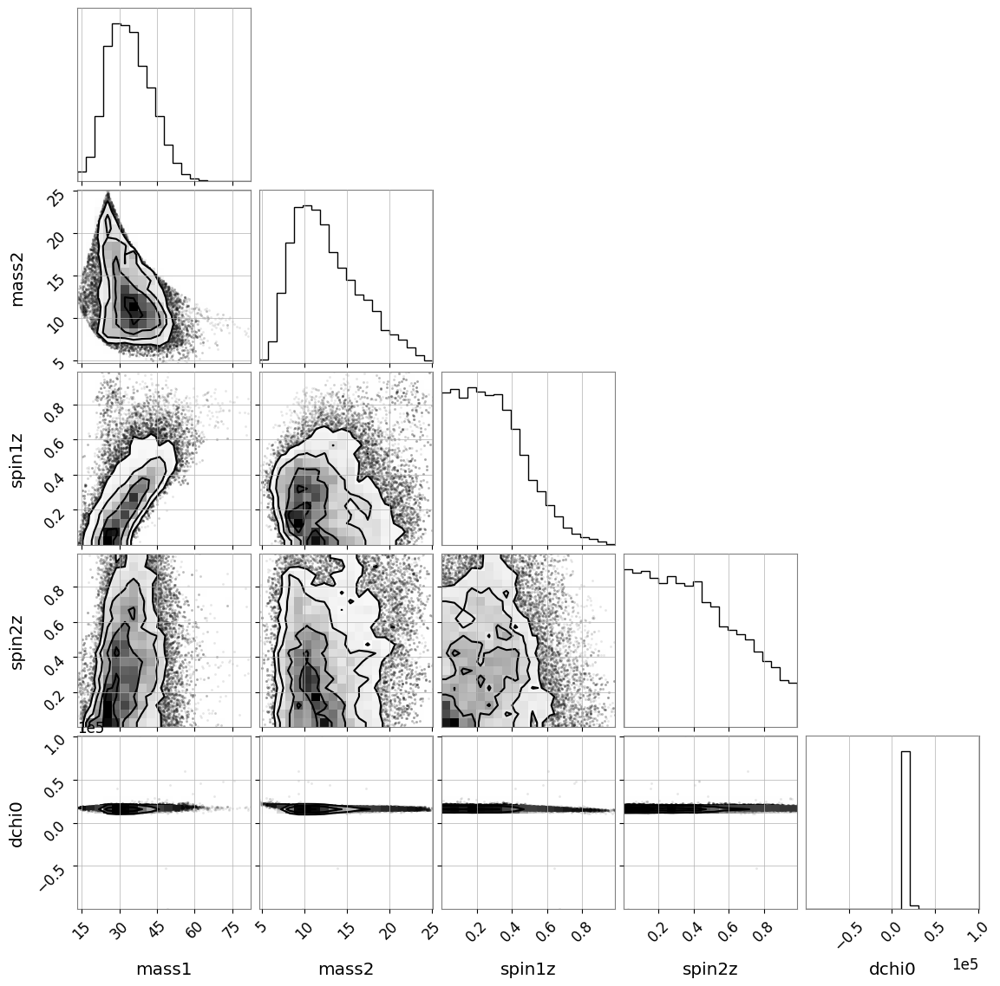

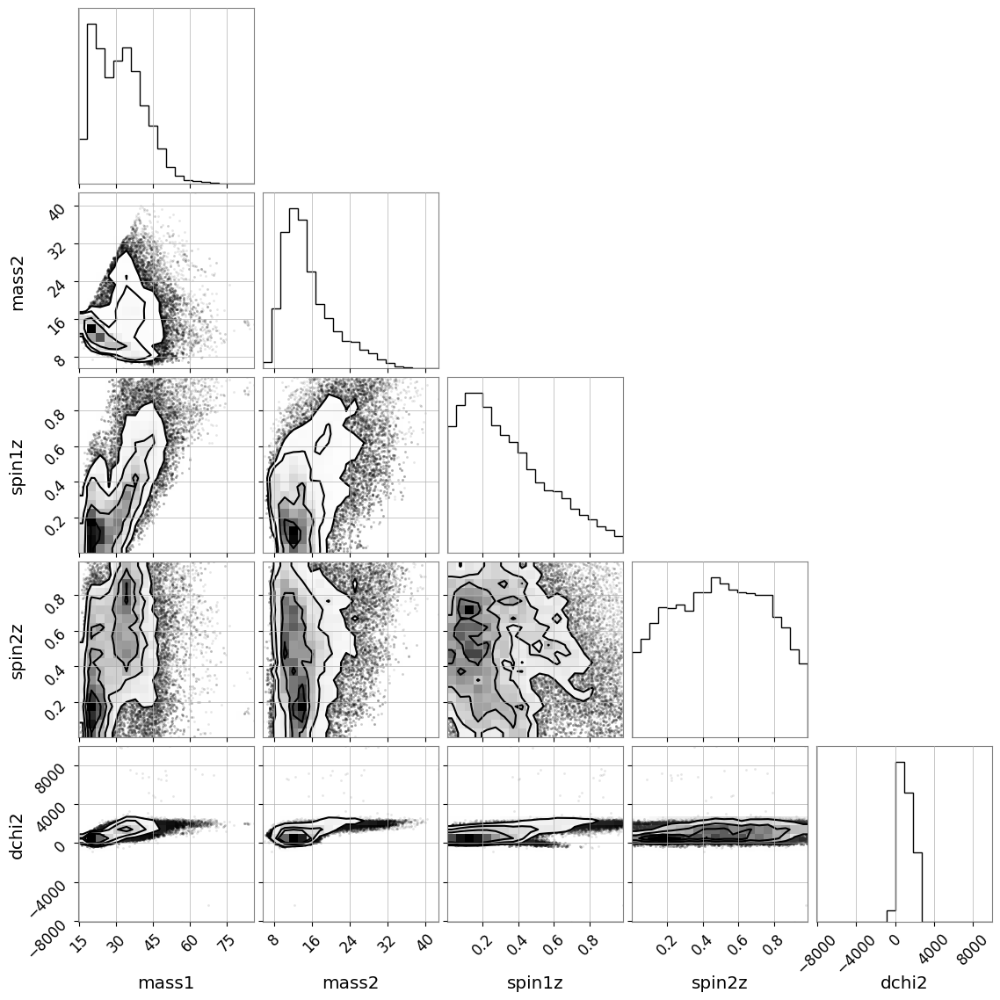

In [88]:
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi0']
corner.corner(samples['GW151012']['cpsi0'][par_list], labels=par_list);

par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi2']
corner.corner(samples['GW151012']['cpsi2'][par_list], labels=par_list);

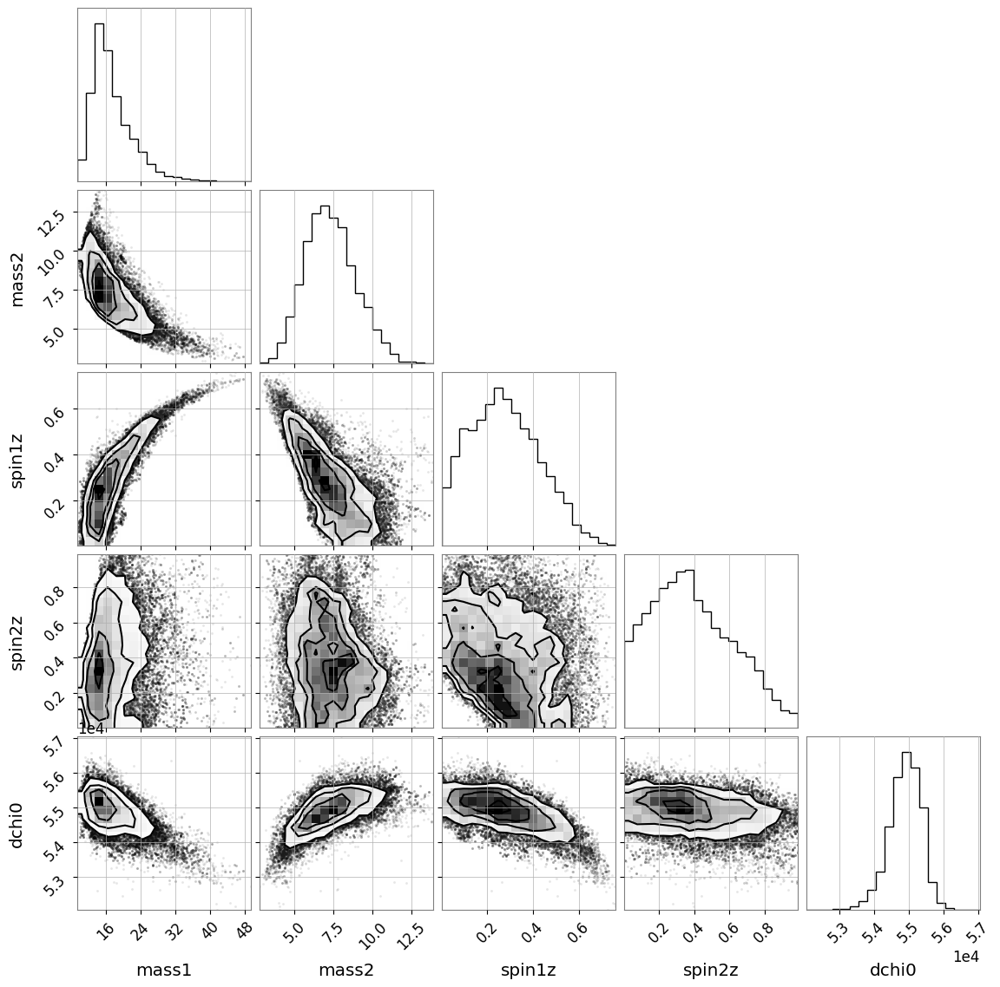

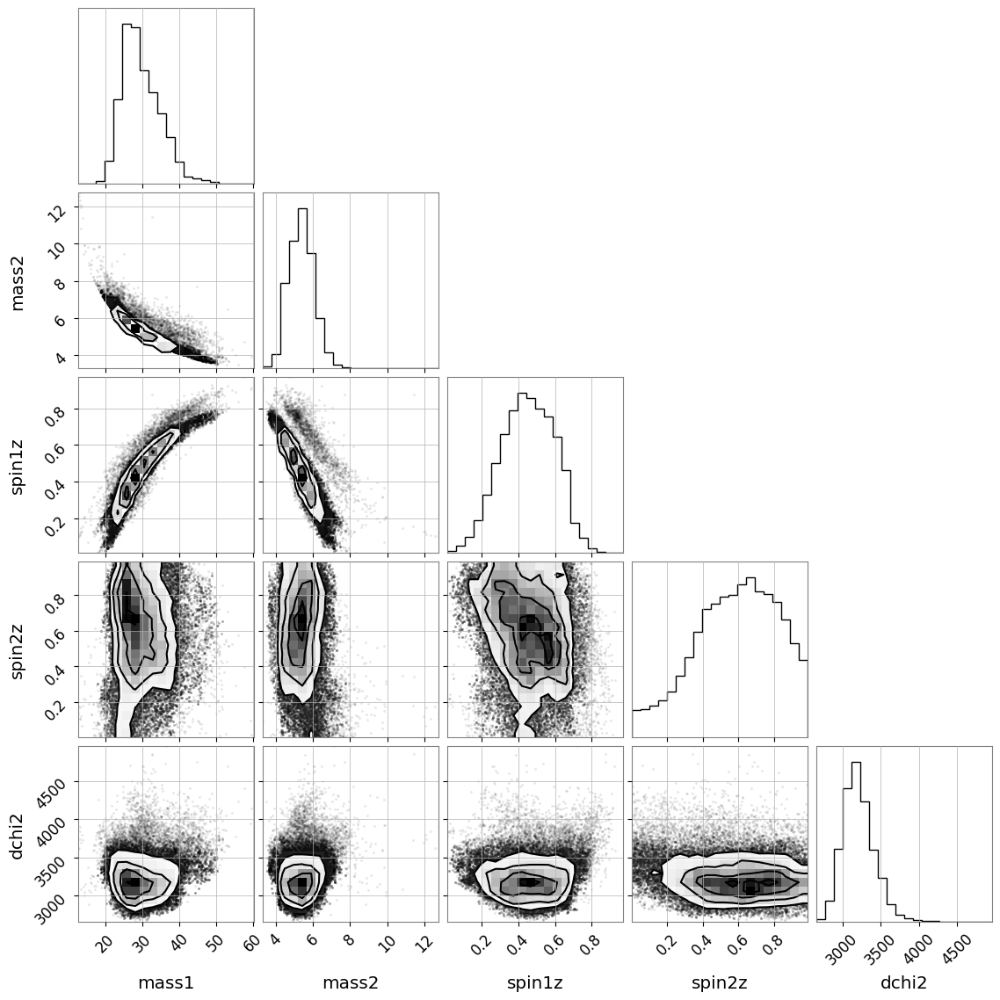

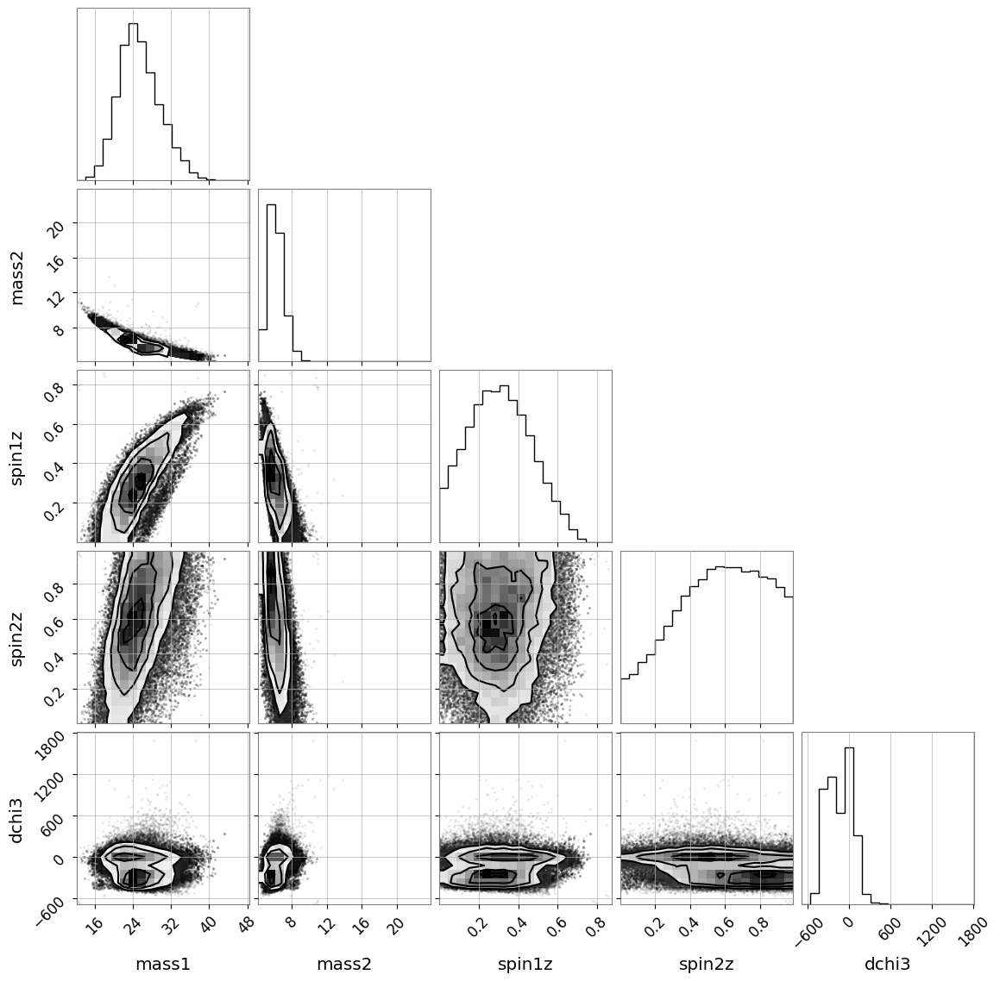

In [128]:
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi0']
corner.corner(samples['GW151226']['cpsi0'][par_list], labels=par_list);
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi2']
corner.corner(samples['GW151226']['cpsi2'][par_list], labels=par_list);
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi3']
corner.corner(samples['GW151226']['cpsi3'][par_list], labels=par_list);

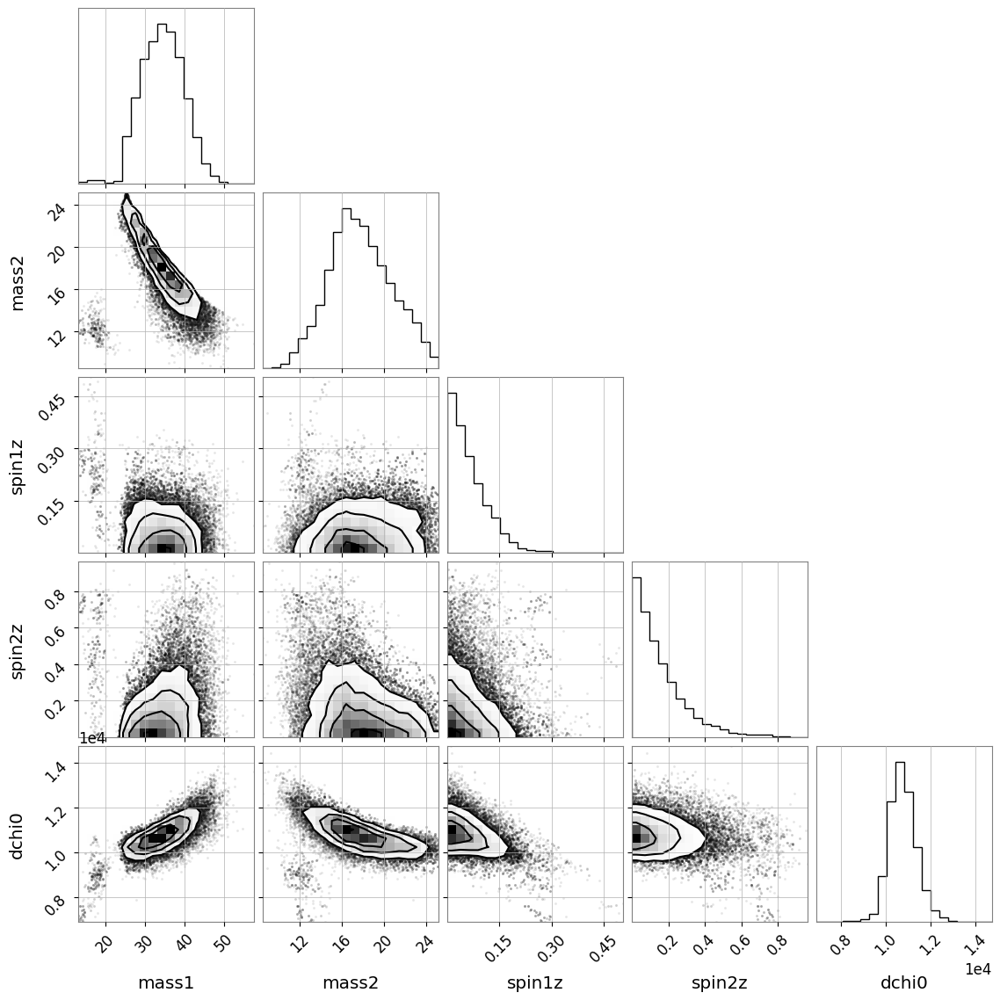

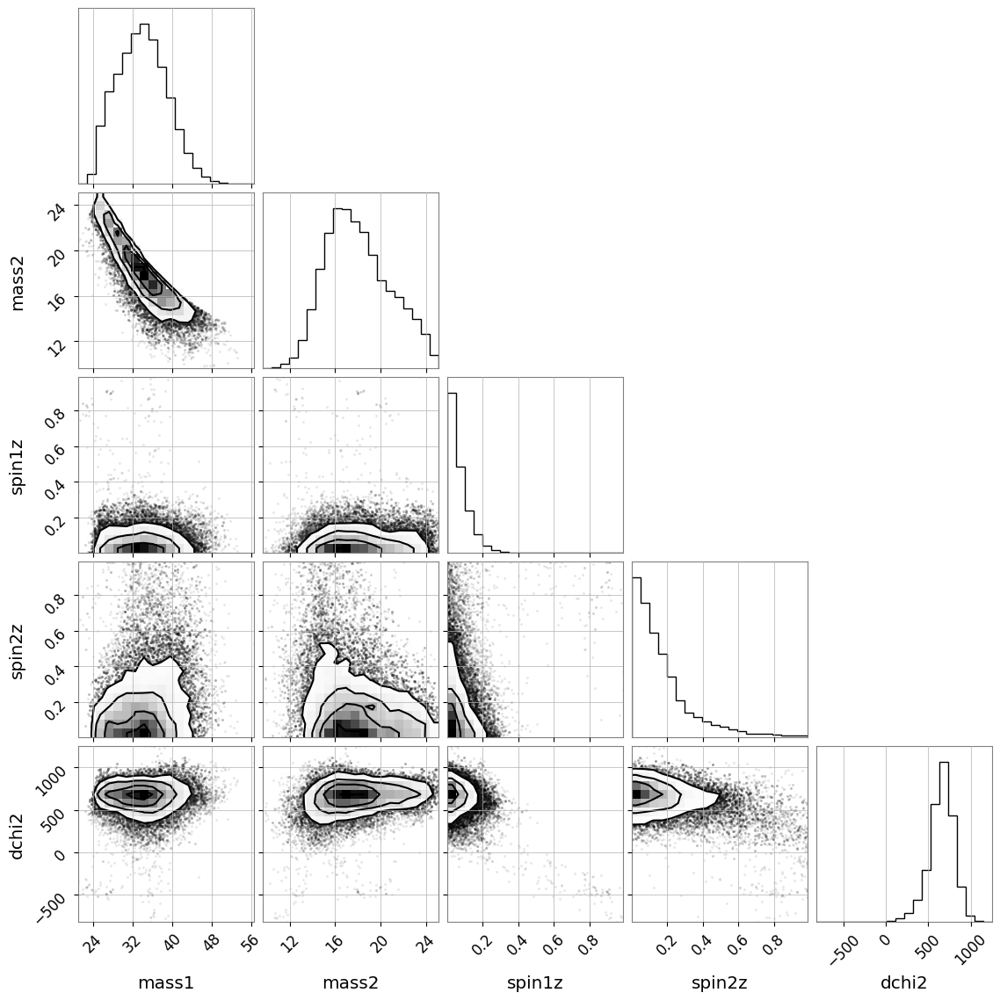

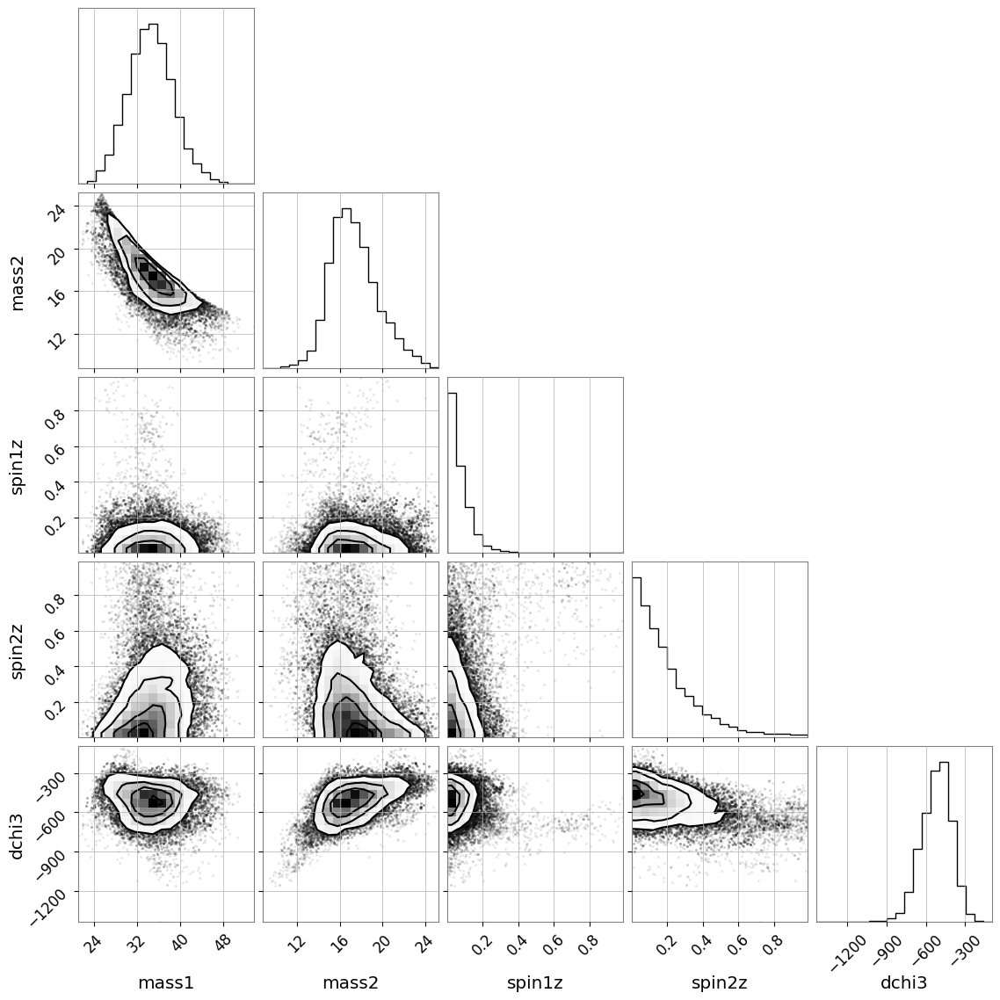

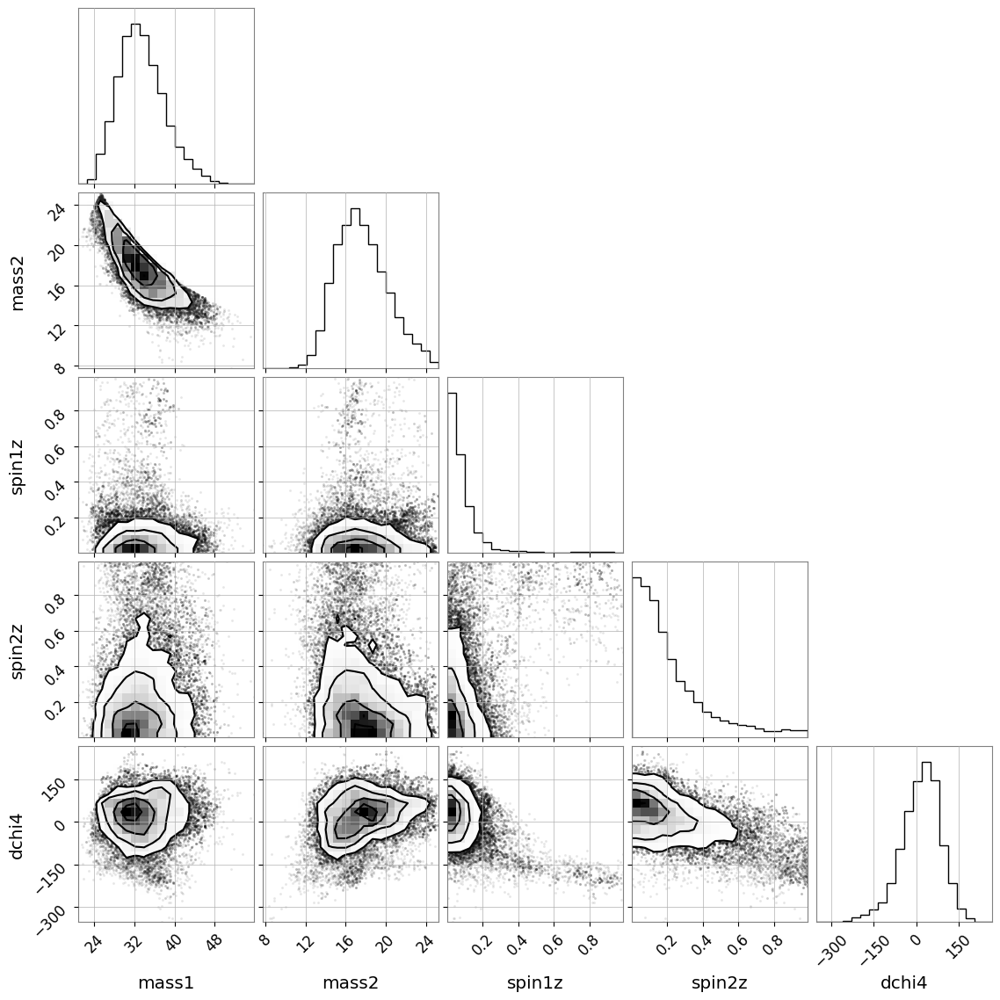

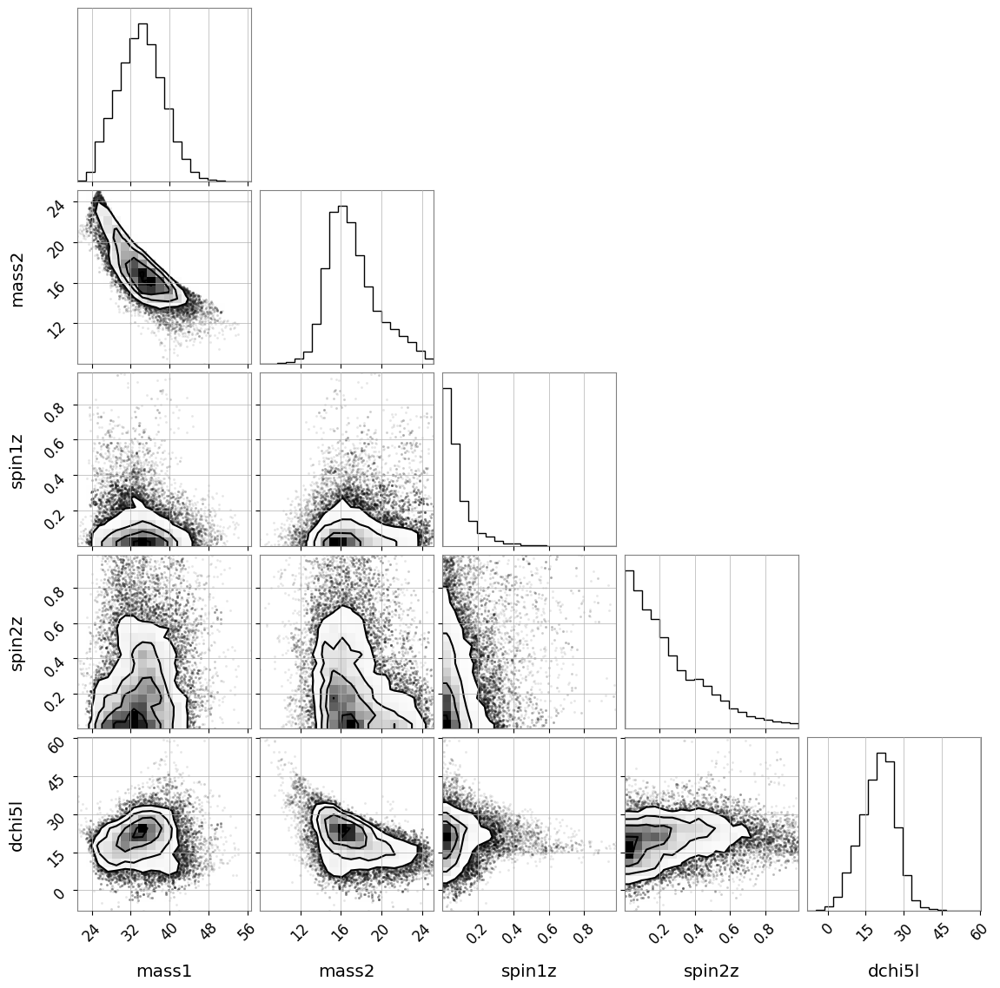

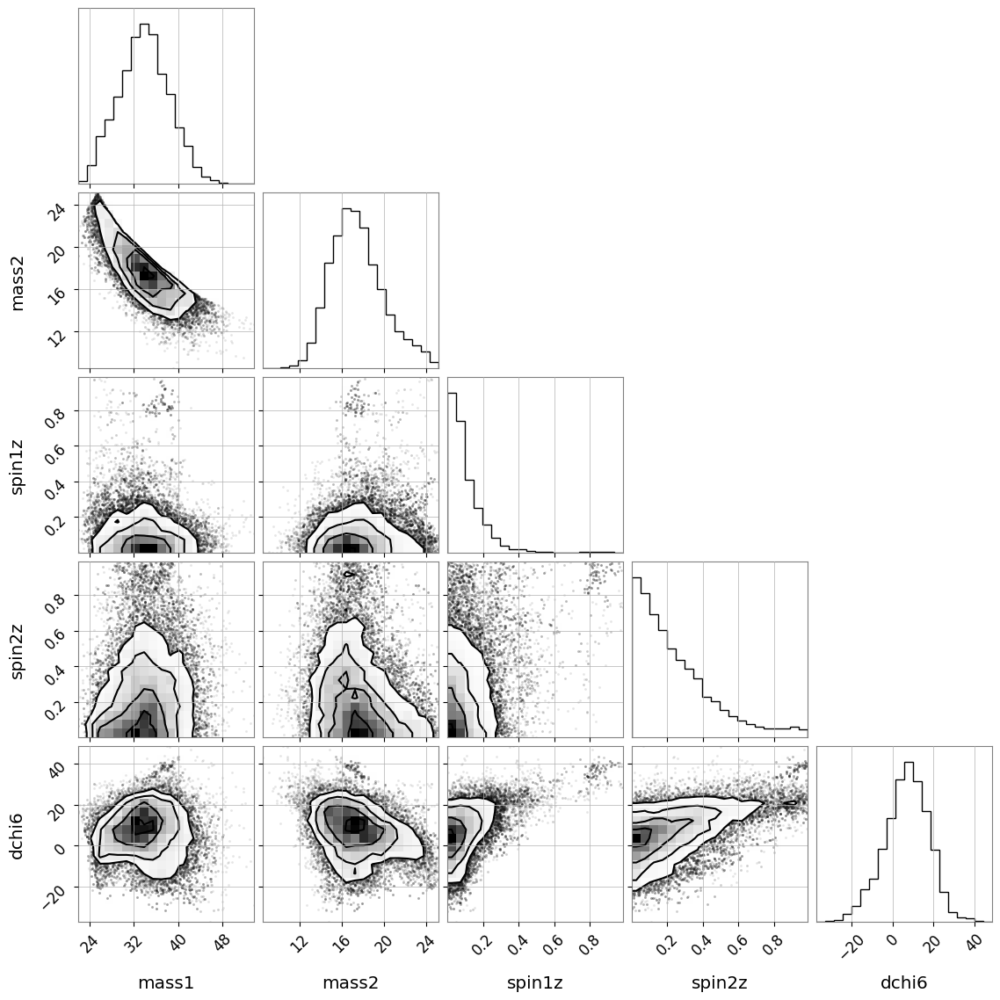

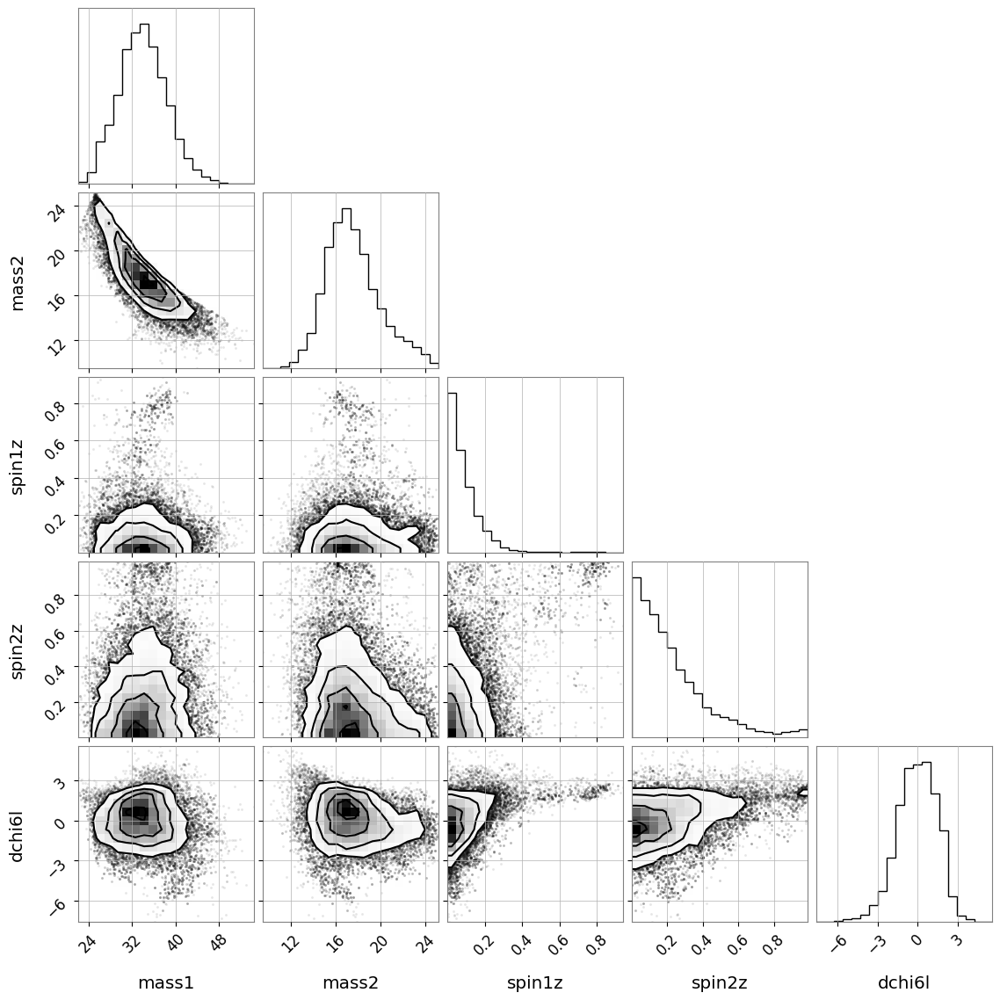

In [45]:
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi0']
corner.corner(samples['GW170104']['cpsi0'][par_list], labels=par_list);

par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi2']
corner.corner(samples['GW170104']['cpsi2'][par_list], labels=par_list);

par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi3']
corner.corner(samples['GW170104']['cpsi3'][par_list], labels=par_list);

par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi4']
corner.corner(samples['GW170104']['cpsi4'][par_list], labels=par_list);

par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi5l']
corner.corner(samples['GW170104']['cpsi5l'][par_list], labels=par_list);

par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi6']
corner.corner(samples['GW170104']['cpsi6'][par_list], labels=par_list);

par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi6l']
corner.corner(samples['GW170104']['cpsi6l'][par_list], labels=par_list);

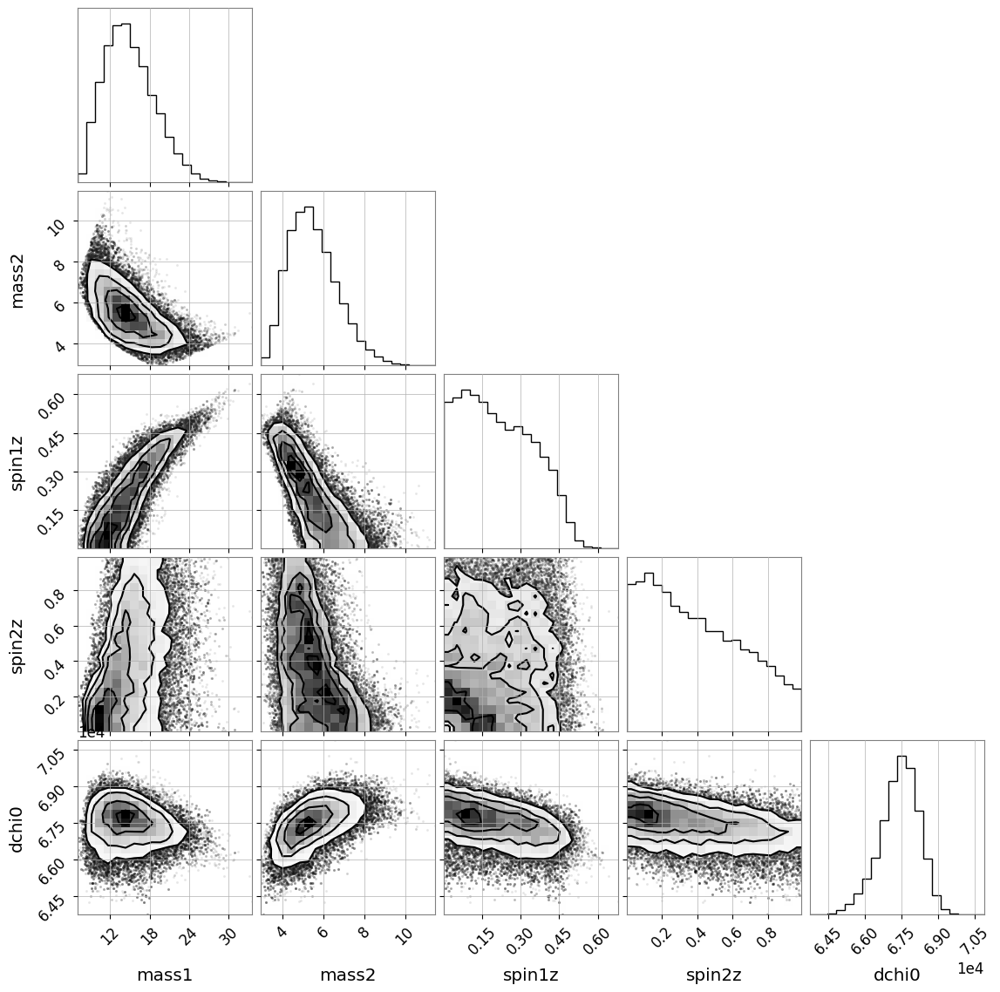

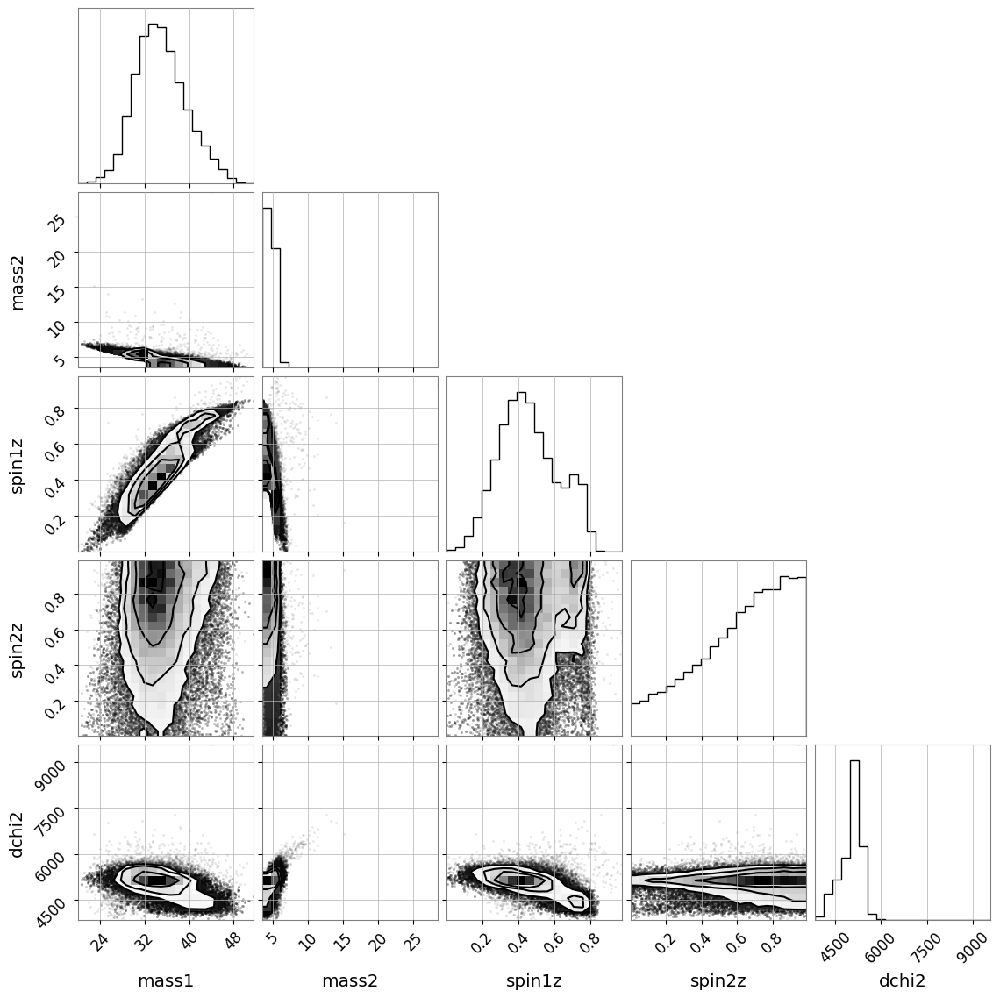

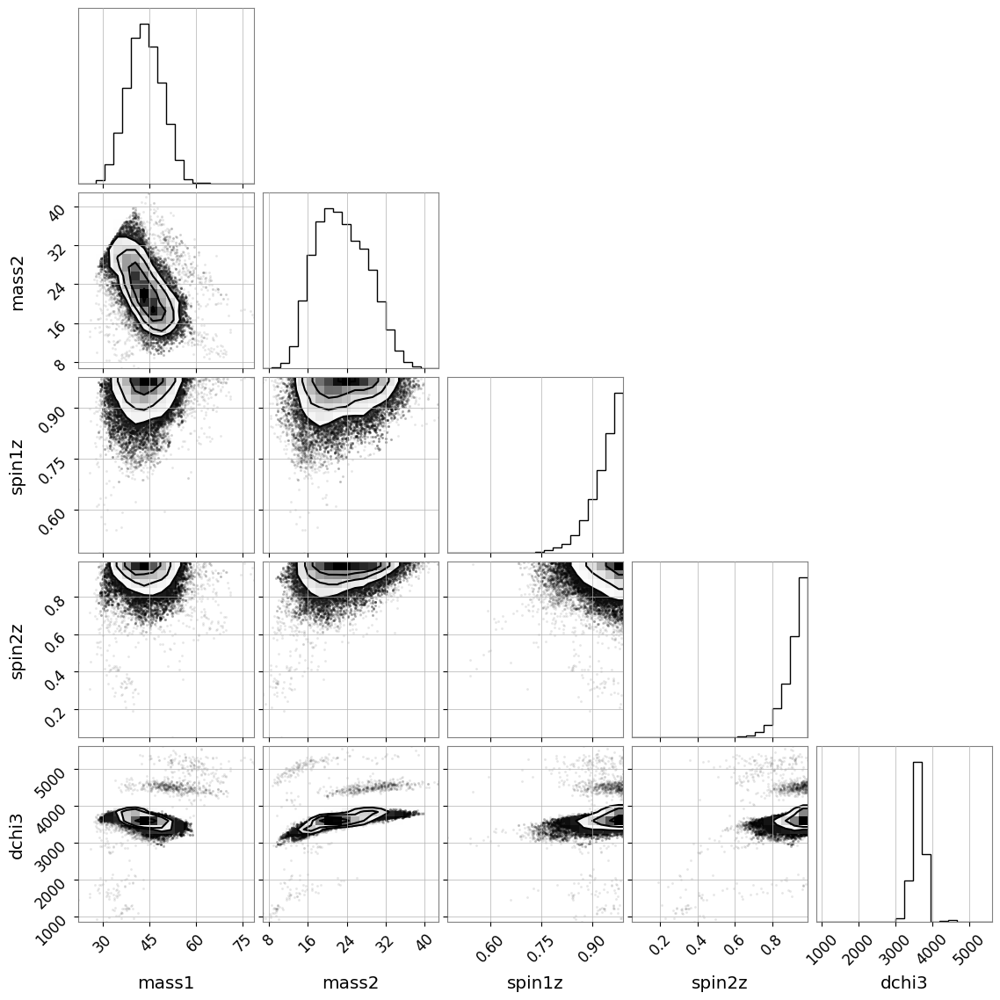

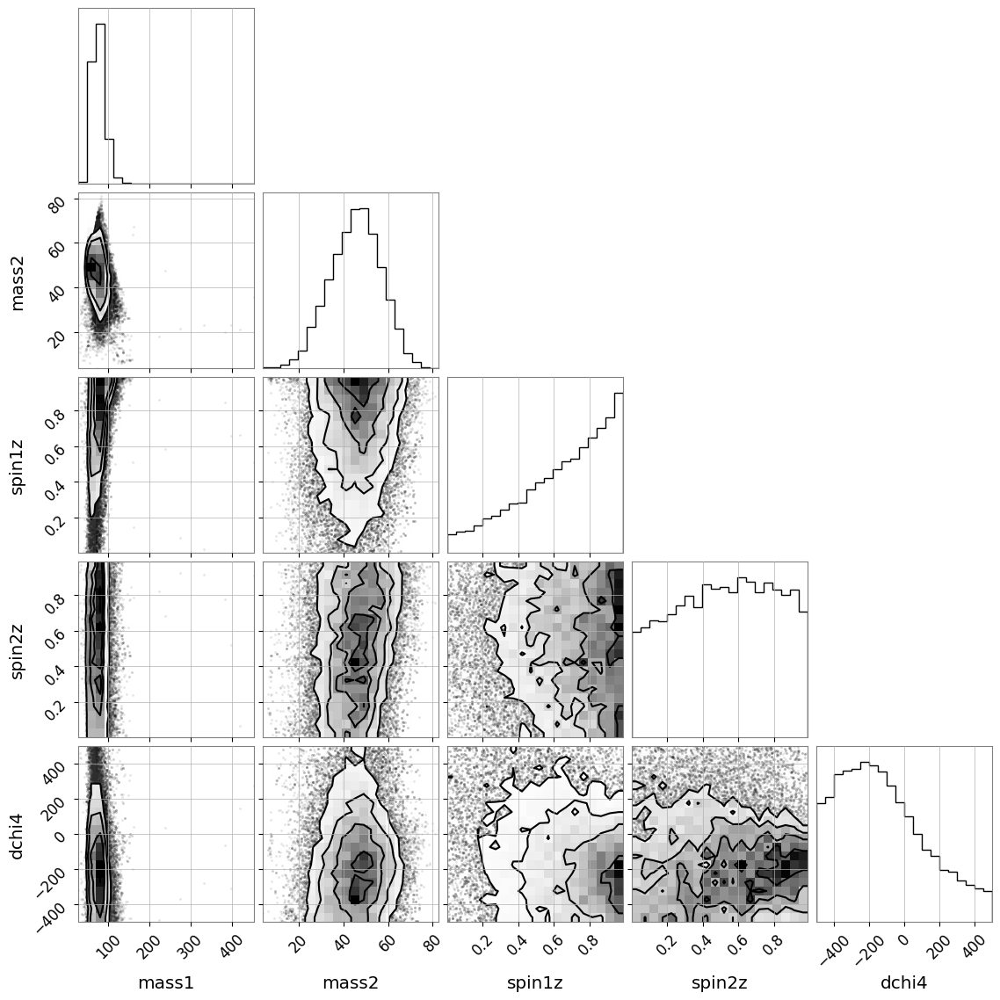

In [111]:
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi0']
corner.corner(samples['GW170608']['cpsi0'][par_list], labels=par_list);
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi2']
corner.corner(samples['GW170608']['cpsi2'][par_list], labels=par_list);
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi3']
corner.corner(samples['GW170608']['cpsi3'][par_list], labels=par_list);
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi4']
corner.corner(samples['GW170608']['cpsi4'][par_list], labels=par_list);

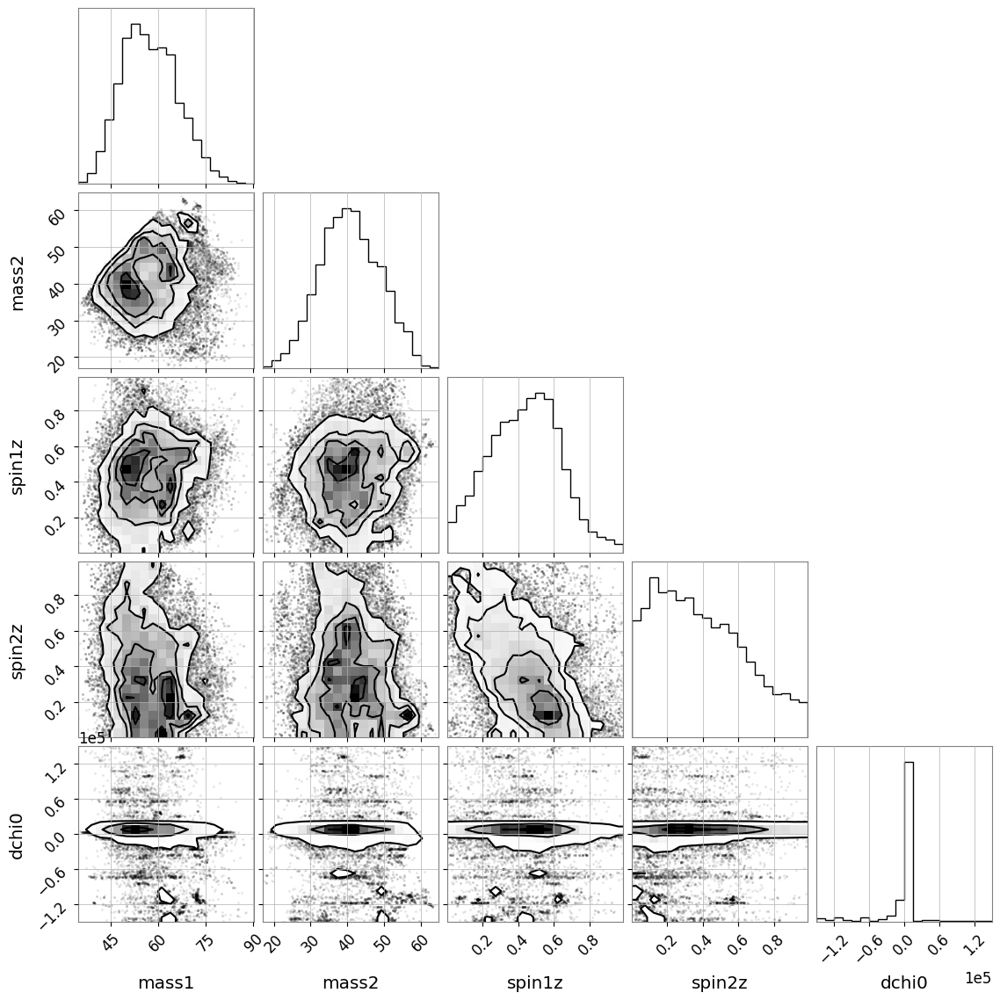

In [69]:
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi0']
corner.corner(samples['GW170729']['cpsi0'][par_list], labels=par_list);

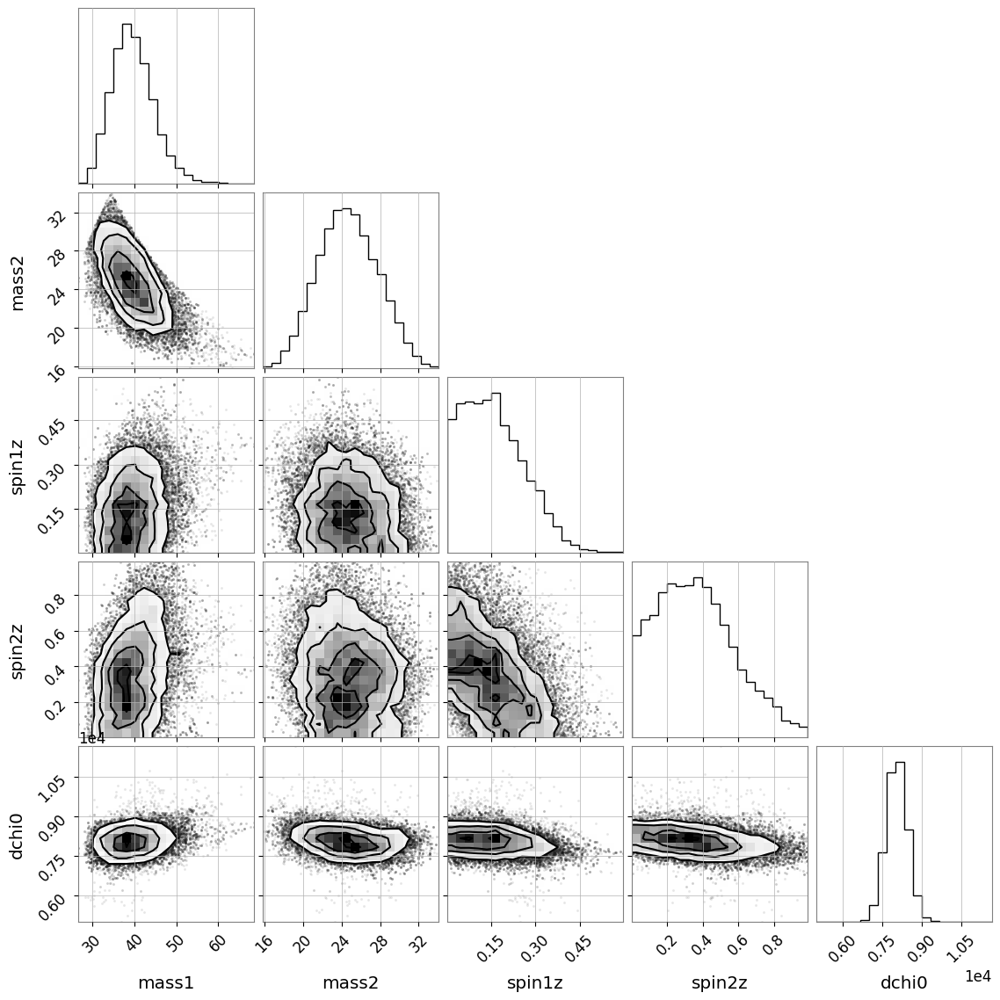

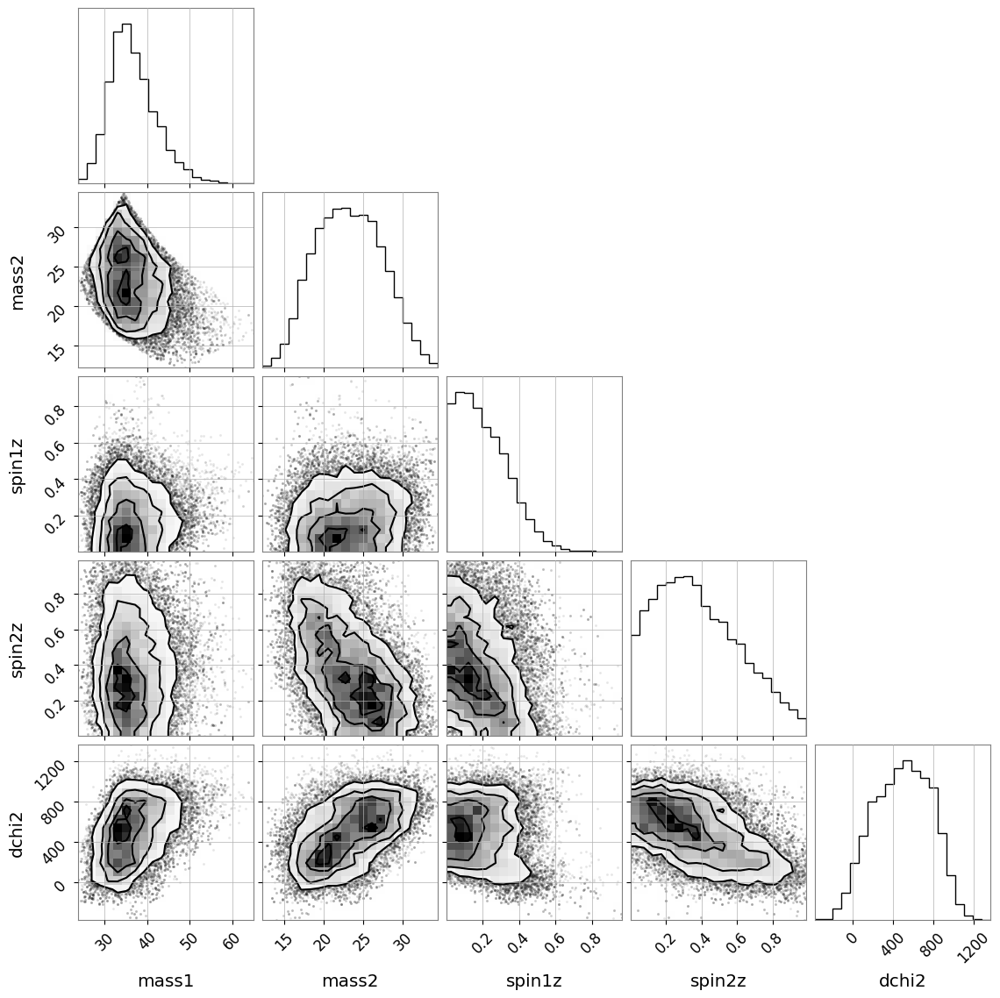

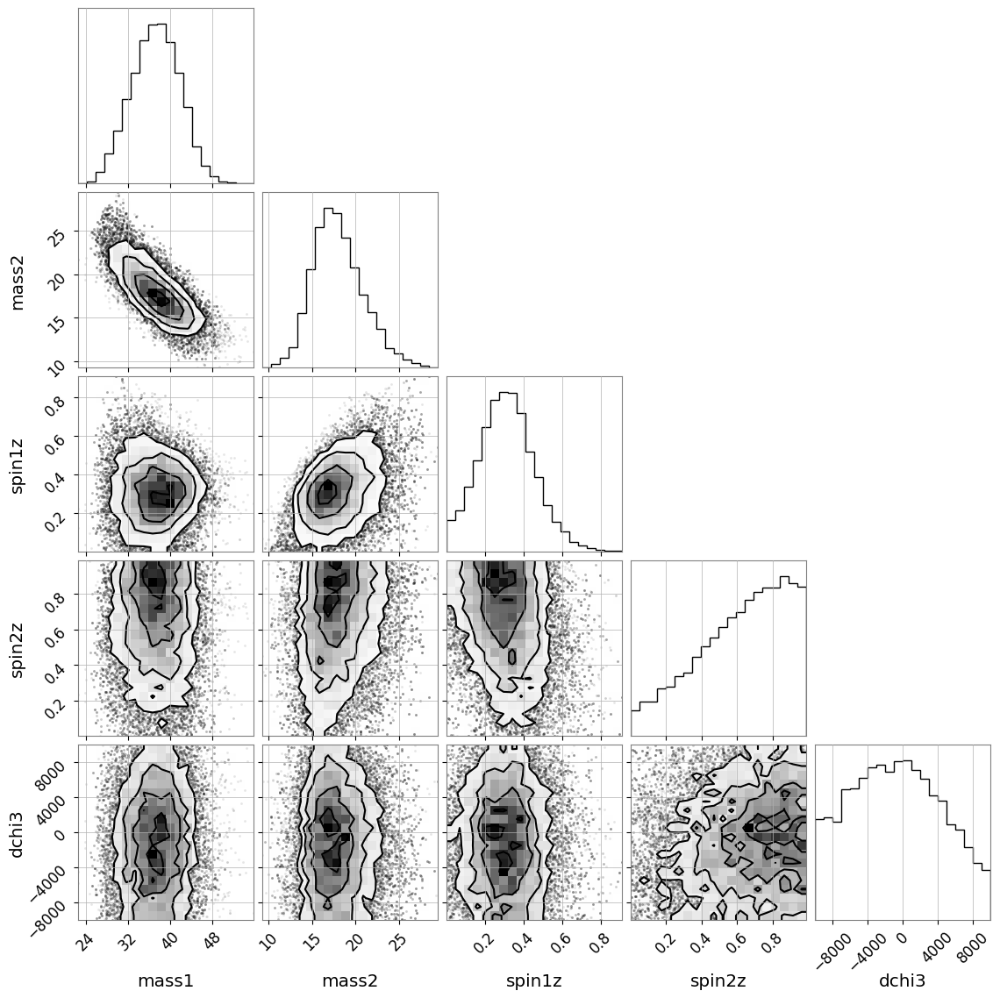

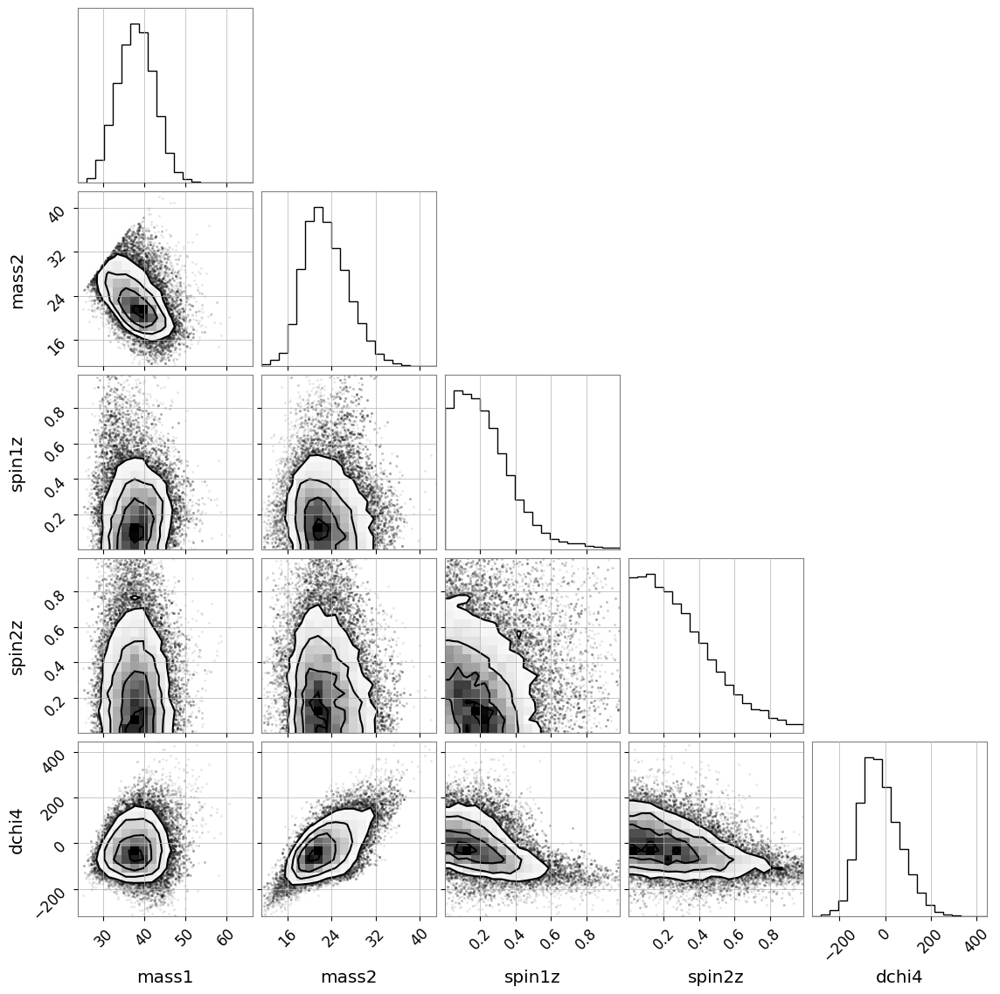

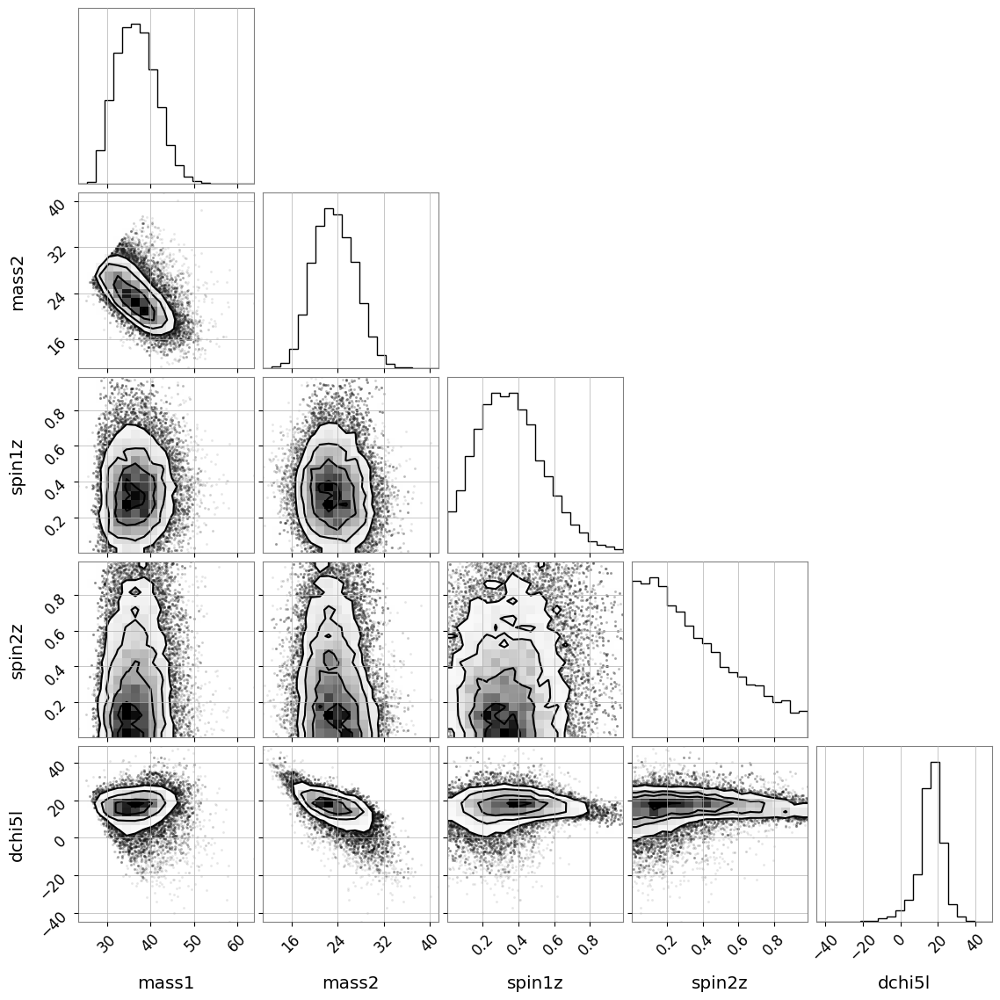

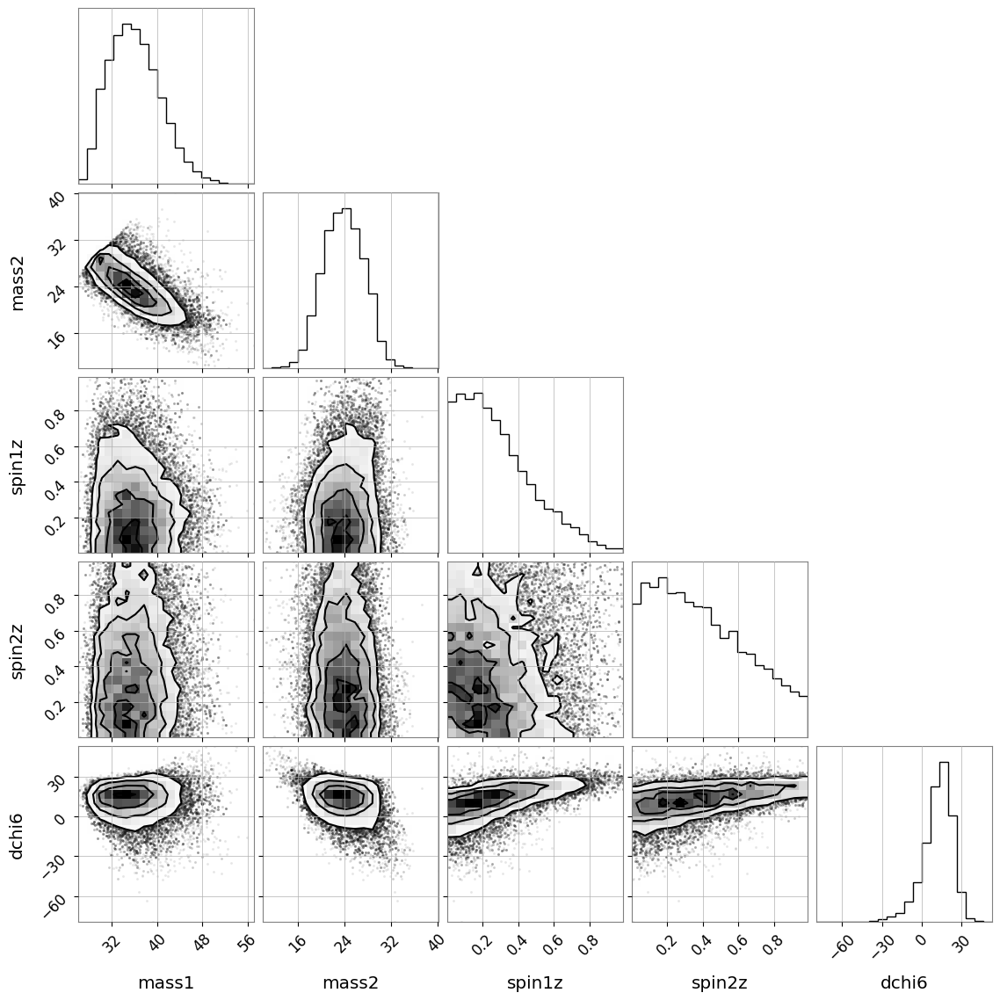

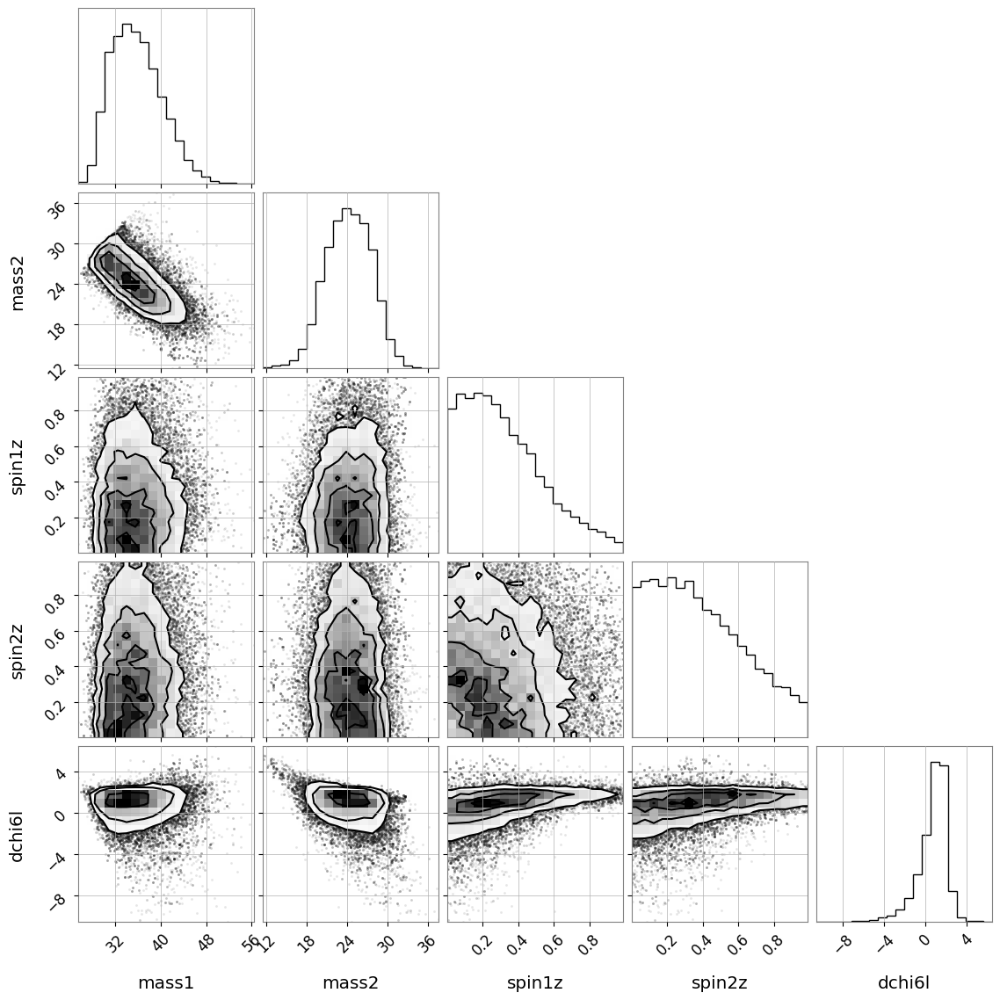

In [137]:
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi0']
corner.corner(samples['GW170809']['cpsi0'][par_list], labels=par_list);
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi2']
corner.corner(samples['GW170809']['cpsi2'][par_list], labels=par_list);
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi3']
corner.corner(samples['GW170809']['cpsi3'][par_list], labels=par_list);
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi4']
corner.corner(samples['GW170809']['cpsi4'][par_list], labels=par_list);
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi5l']
corner.corner(samples['GW170809']['cpsi5l'][par_list], labels=par_list);
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi6']
corner.corner(samples['GW170809']['cpsi6'][par_list], labels=par_list);
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi6l']
corner.corner(samples['GW170809']['cpsi6l'][par_list], labels=par_list);

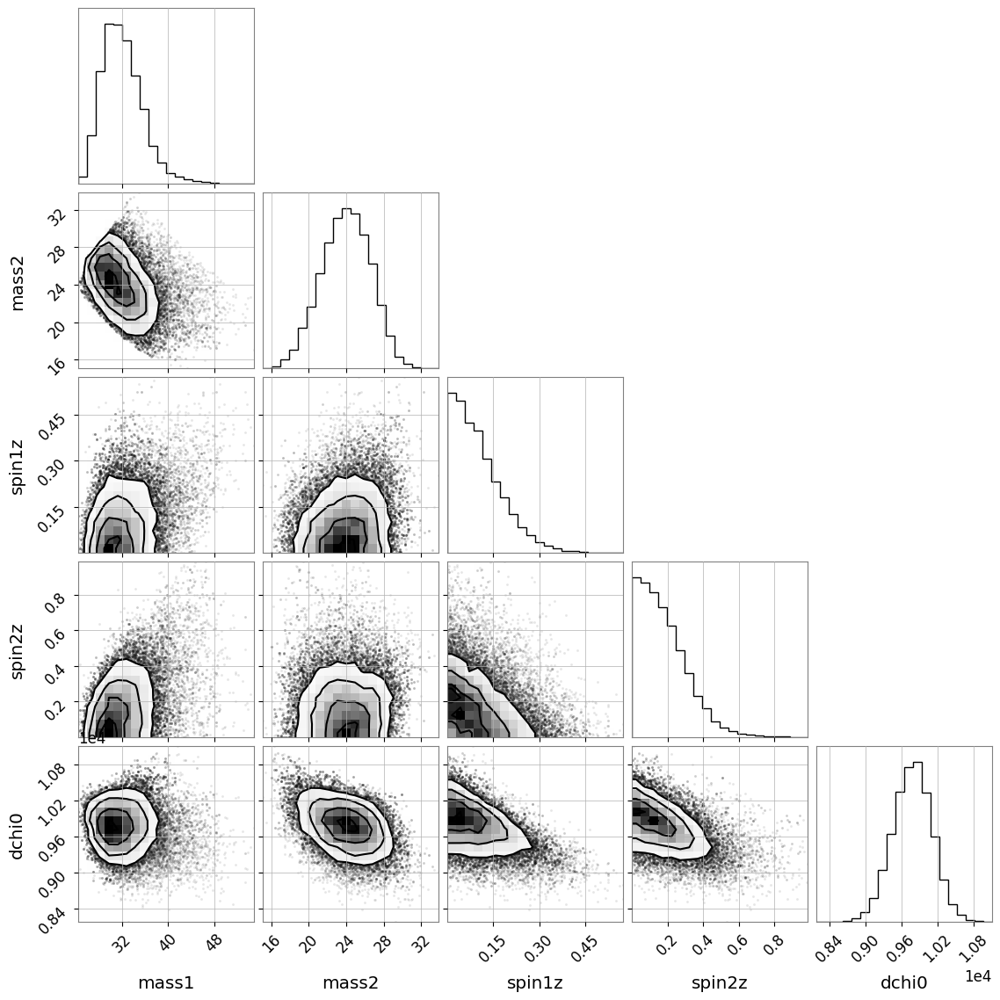

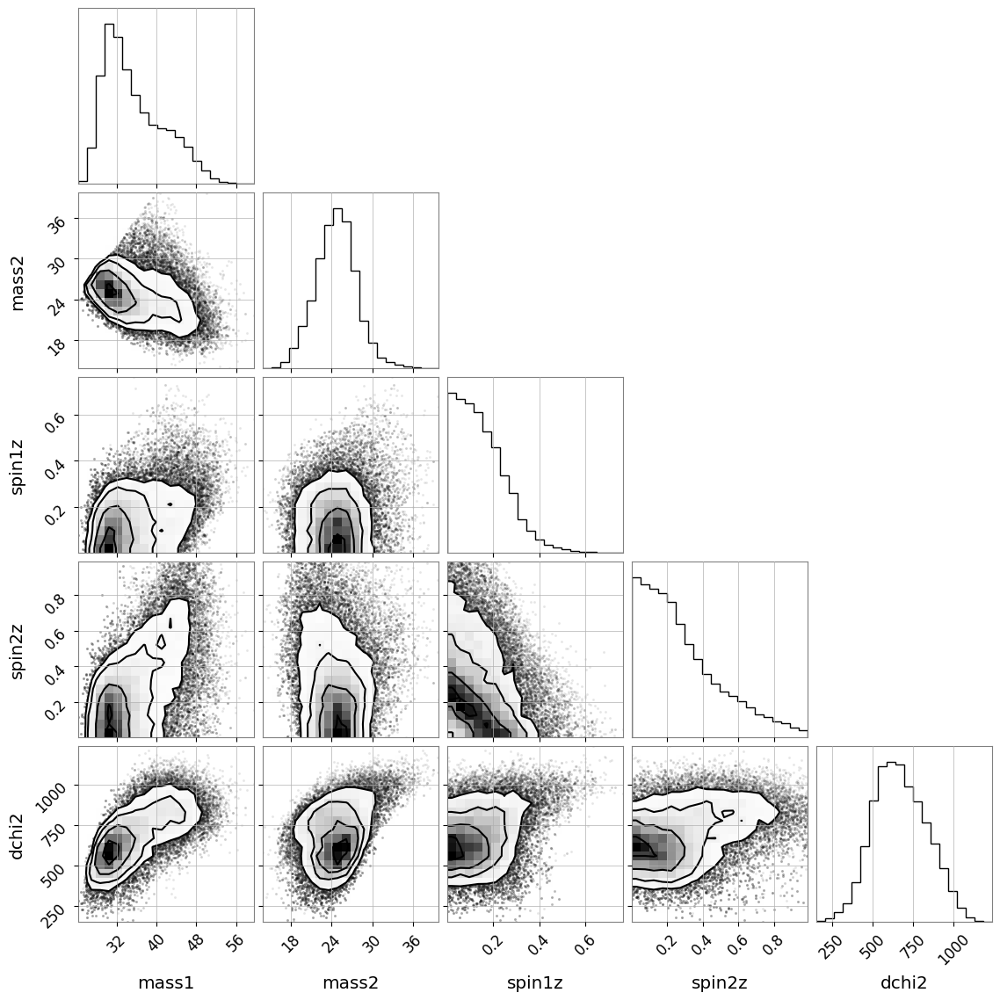

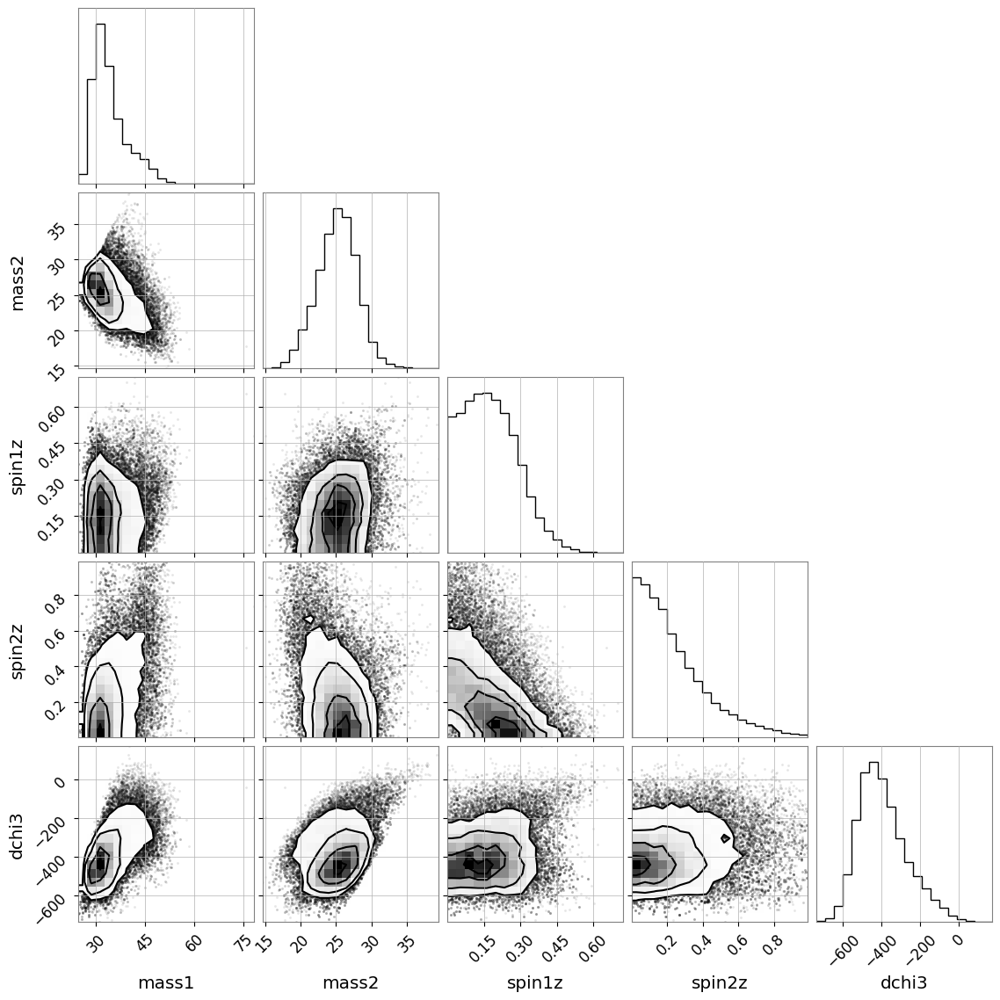

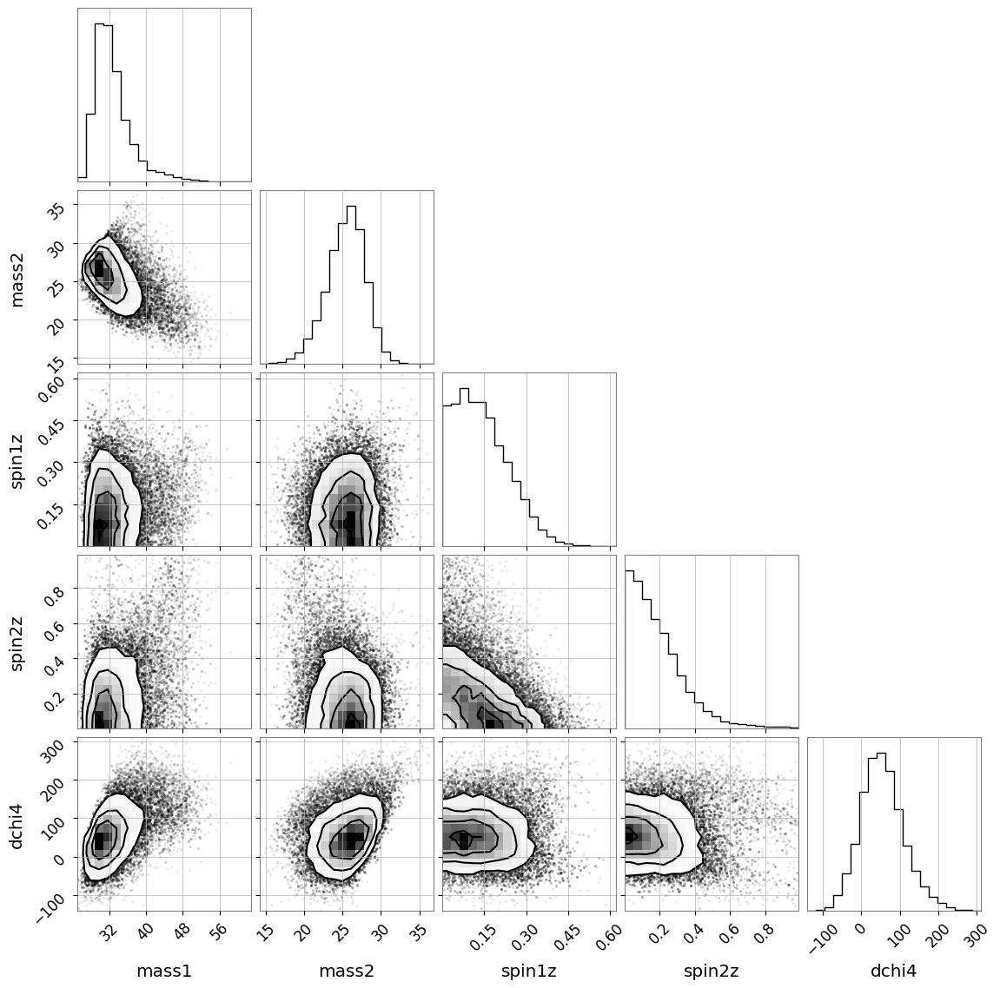

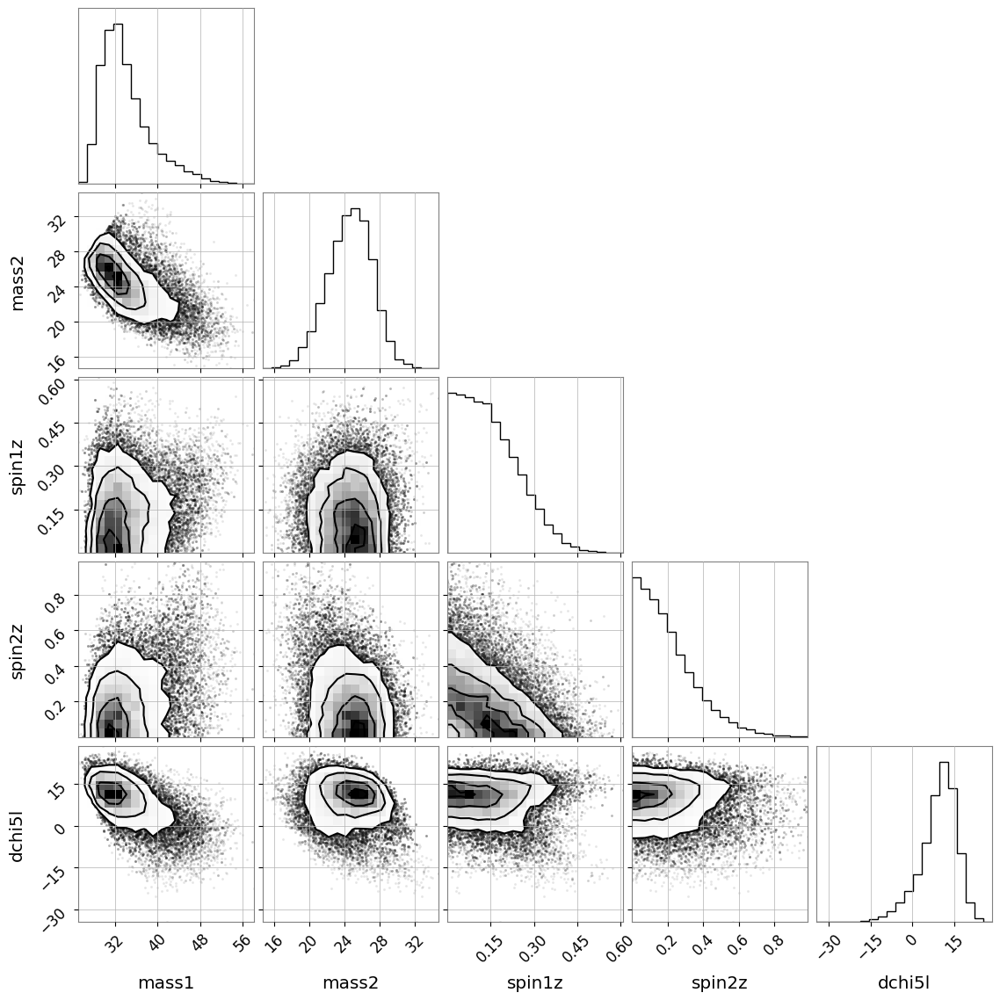

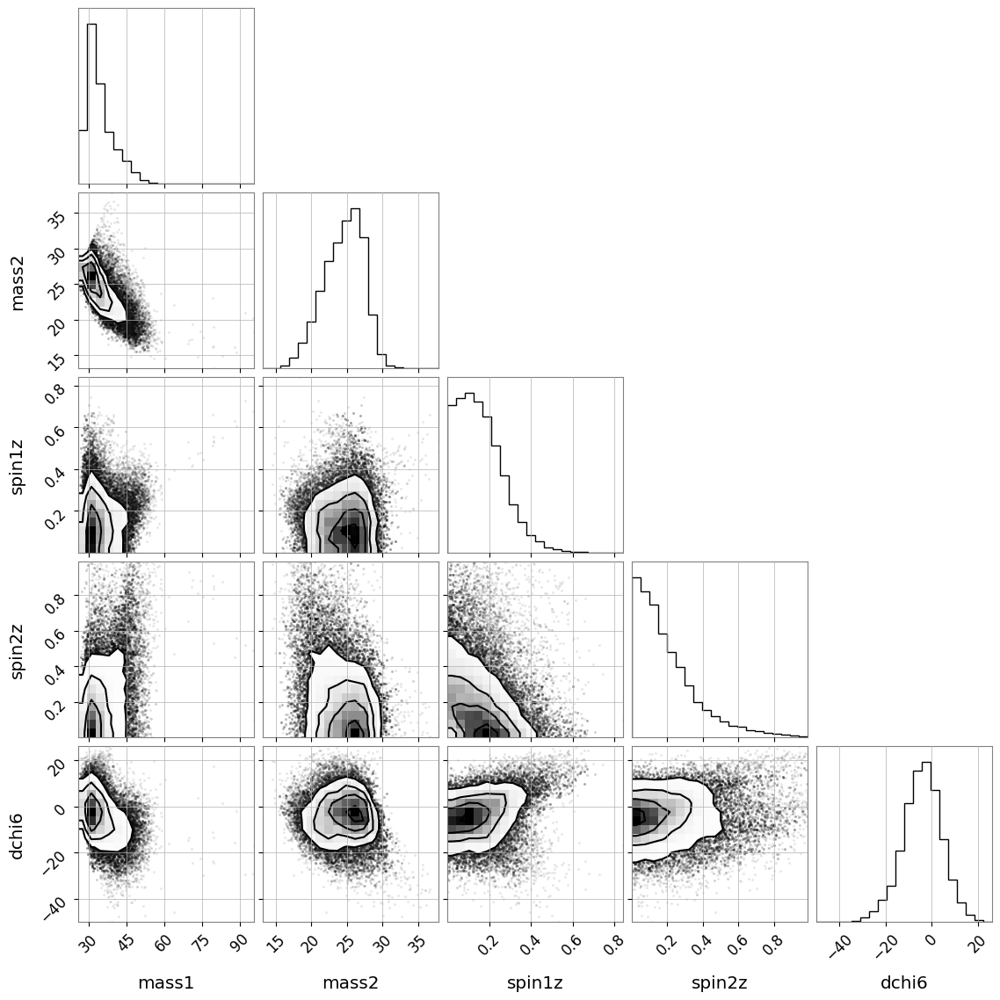

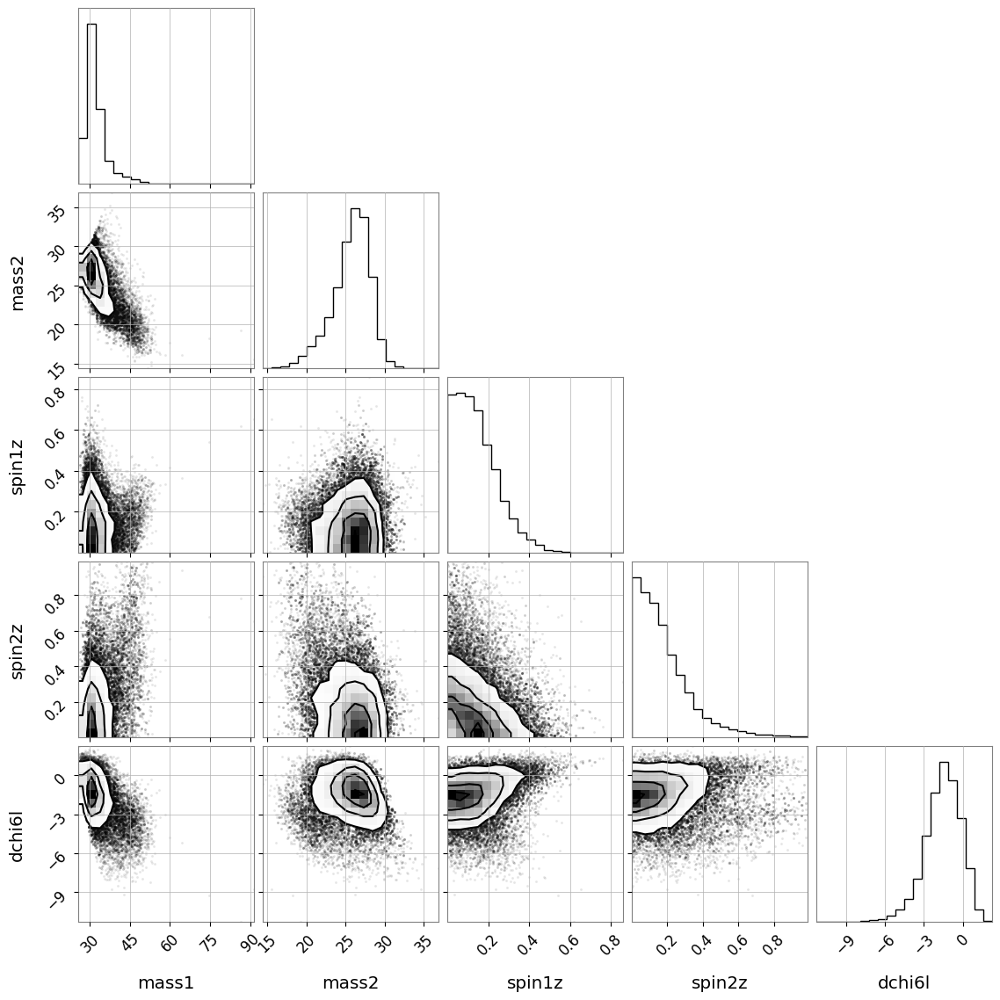

In [138]:
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi0']
corner.corner(samples['GW170814']['cpsi0'][par_list], labels=par_list);
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi2']
corner.corner(samples['GW170814']['cpsi2'][par_list], labels=par_list);
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi3']
corner.corner(samples['GW170814']['cpsi3'][par_list], labels=par_list);
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi4']
corner.corner(samples['GW170814']['cpsi4'][par_list], labels=par_list);
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi5l']
corner.corner(samples['GW170814']['cpsi5l'][par_list], labels=par_list);
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi6']
corner.corner(samples['GW170814']['cpsi6'][par_list], labels=par_list);
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi6l']
corner.corner(samples['GW170814']['cpsi6l'][par_list], labels=par_list);

In [143]:
samples['GW170814']['cpsi6l']["mass1"].min()

25.654444207976034

(-10000.0, 10000.0)

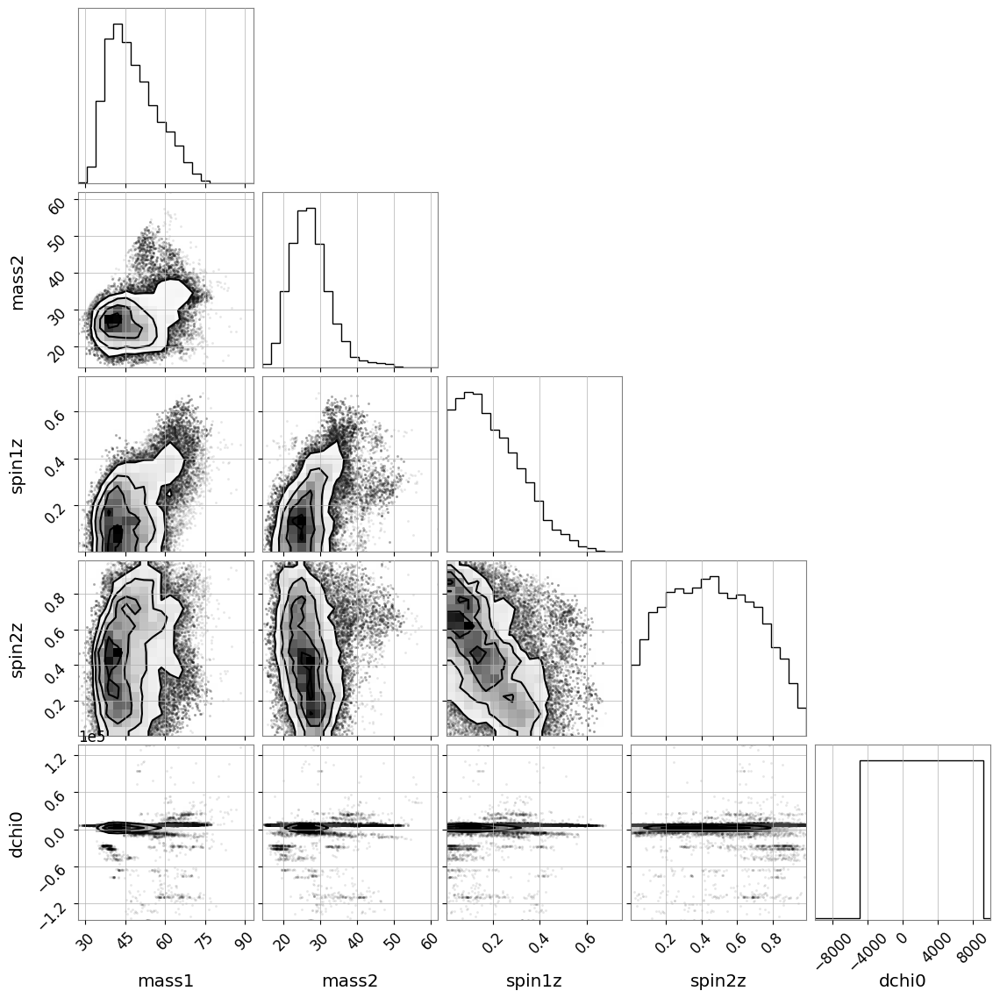

In [72]:
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi0']
corner.corner(samples['GW170818']['cpsi0'][par_list], labels=par_list);
pp.xlim([-1e4,1e4])

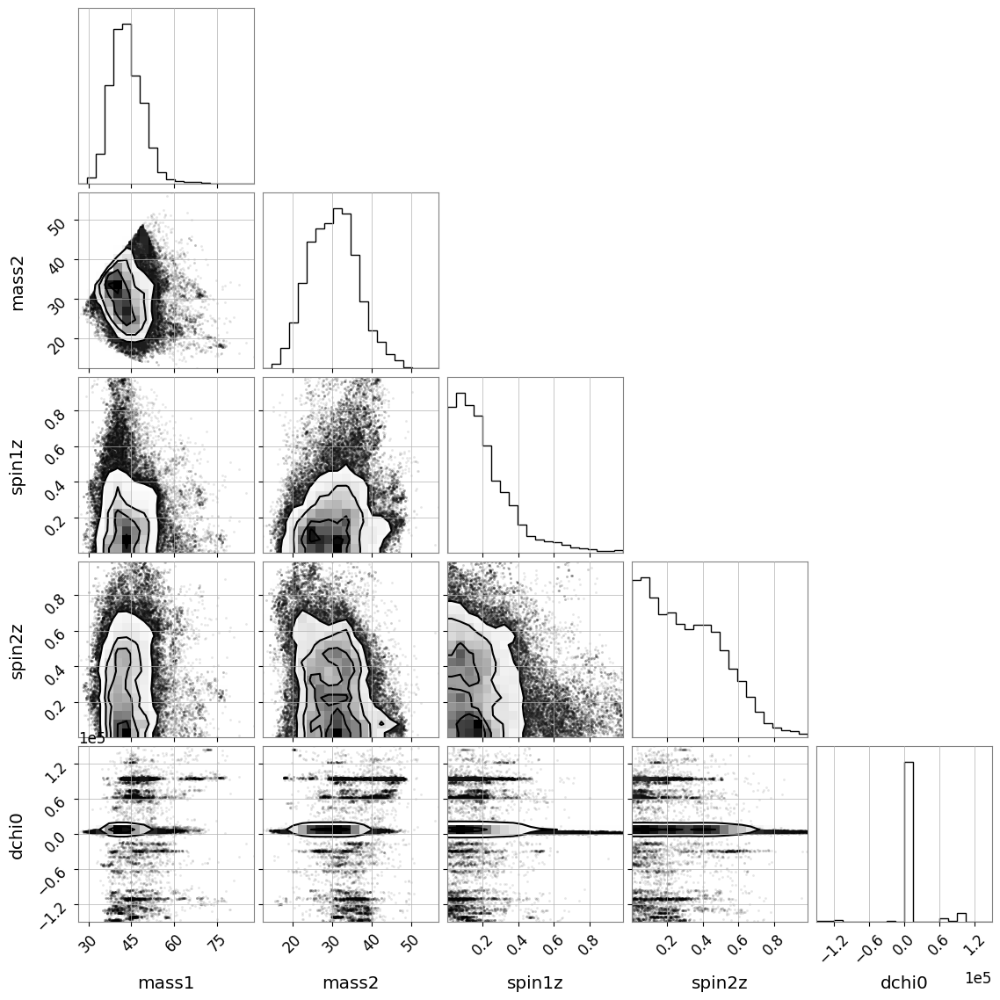

In [58]:
par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'dchi0']
corner.corner(samples['GW170823']['cpsi0'][par_list], labels=par_list);

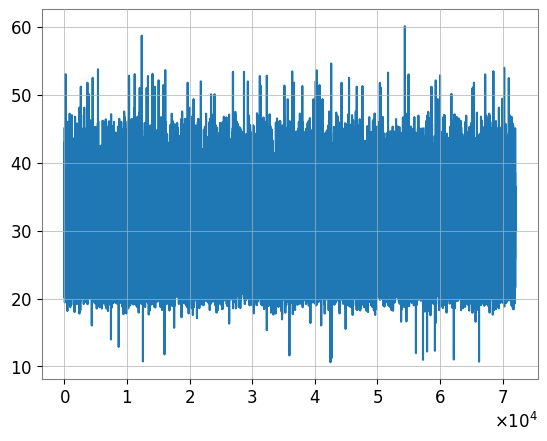

In [45]:
pp.plot(samples['GW170818']['cpsi0']['mass2'])

In [ ]:
# 随机性，收敛性


In [43]:
min(samples['GW170818']['cpsi0']["dchi0"])

-109096.02867642118

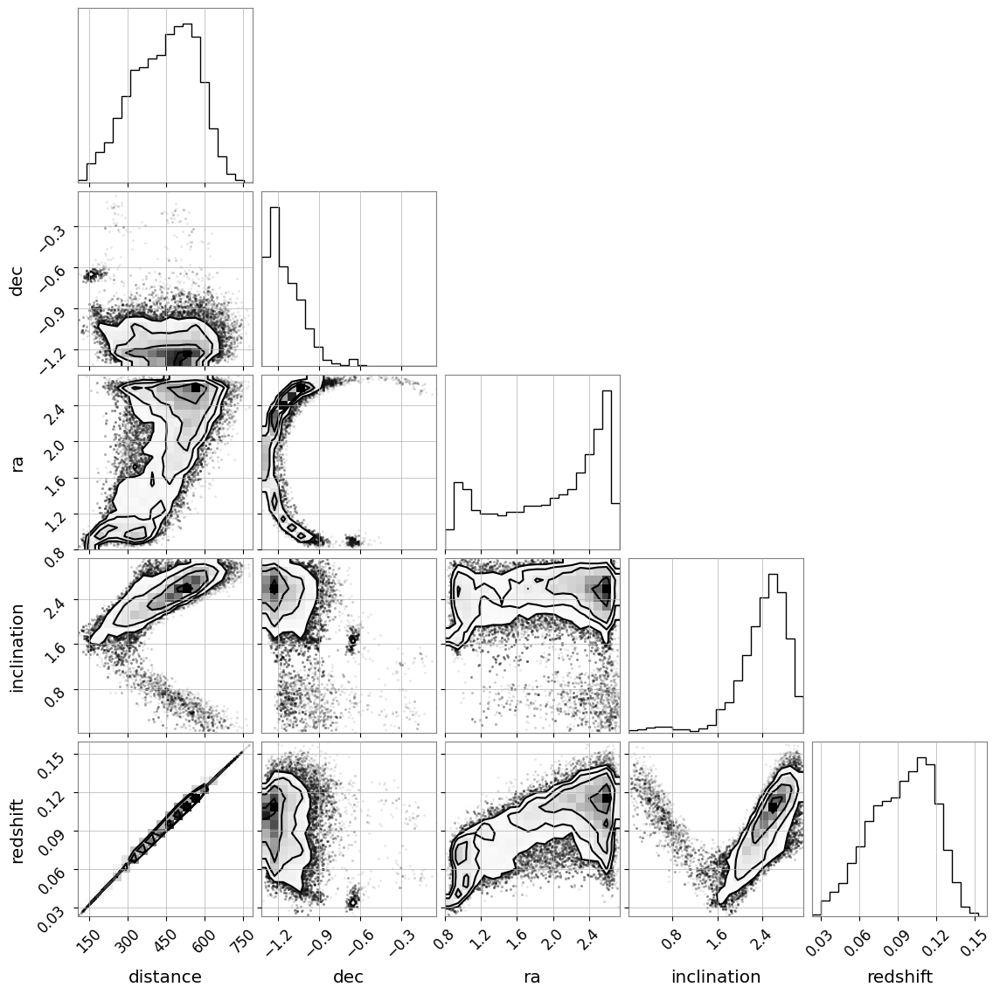

In [44]:
# par_list = ['distance', 'dec', 'ra', 'inclination', 'redshift']
# corner.corner(samples['GW150914']['cpsi3'][par_list], labels=par_list);

# par_list = ['distance', 'dec', 'ra', 'inclination', 'redshift']
# corner.corner(samples['GW150914']['fdchi3'][par_list], labels=par_list);

# par_list = ['distance', 'dec', 'ra', 'inclination', 'redshift']
# corner.corner(samples['GW150914']['cpsi4'][par_list], labels=par_list);

# par_list = ['distance', 'dec', 'ra', 'inclination', 'redshift']
# corner.corner(samples['GW150914']['fdchi4'][par_list], labels=par_list);

# par_list = ['distance', 'dec', 'ra', 'inclination', 'redshift']
# corner.corner(samples['GW150914']['cpsi6l'][par_list], labels=par_list);

# par_list = ['distance', 'dec', 'ra', 'inclination', 'redshift']
# corner.corner(samples['GW150914']['fdchi6l'][par_list], labels=par_list);

# par_list = ['distance', 'dec', 'ra', 'inclination', 'redshift']
# corner.corner(samples['GW200129_065458']['GR'][par_list], labels=par_list);

# par_list = ['distance', 'dec', 'ra', 'inclination', 'redshift']
# corner.corner(samples['GW200129_065458']['cpsi4'][par_list], labels=par_list);


par_list = ['distance', 'dec', 'ra', 'inclination', 'redshift']
corner.corner(samples['GW150914_095045']['cpsi3'][par_list], labels=par_list);

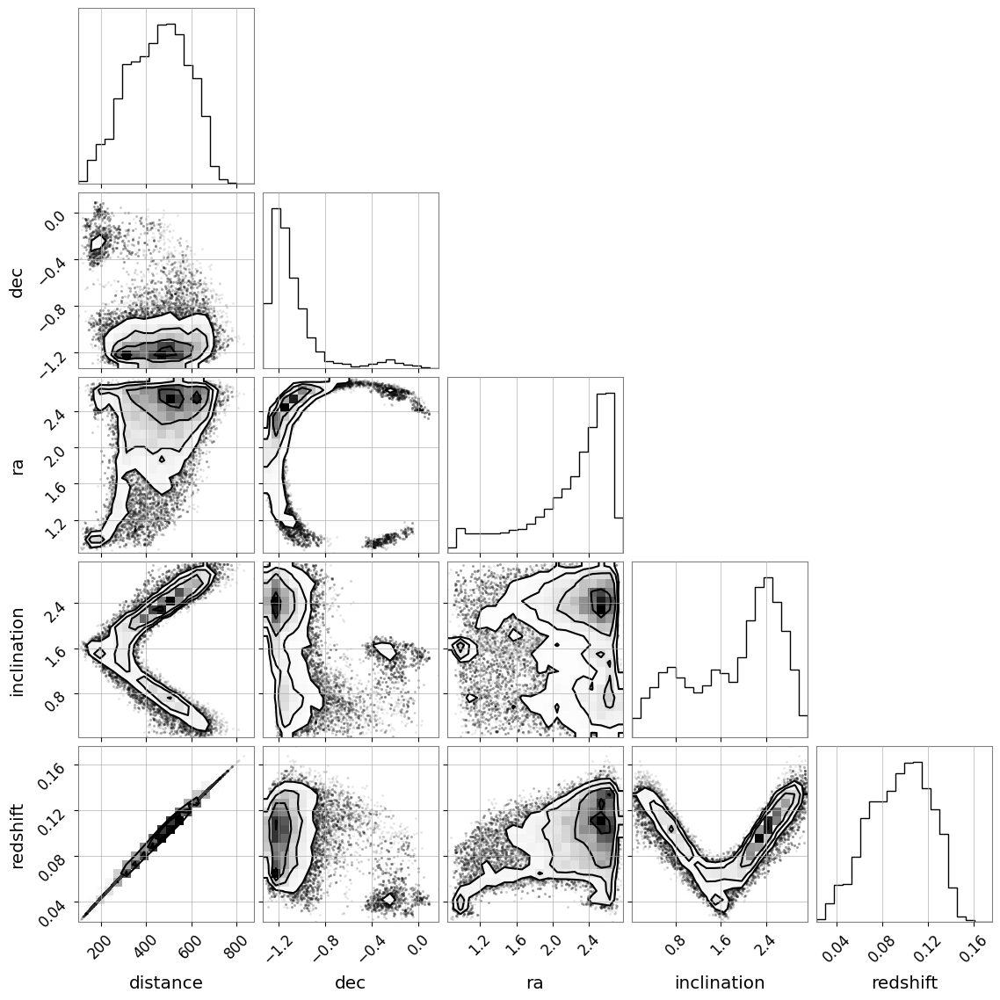

In [23]:

par_list = ['distance', 'dec', 'ra', 'inclination', 'redshift']
corner.corner(samples['GW151012']['cpsi0'][par_list], labels=par_list);

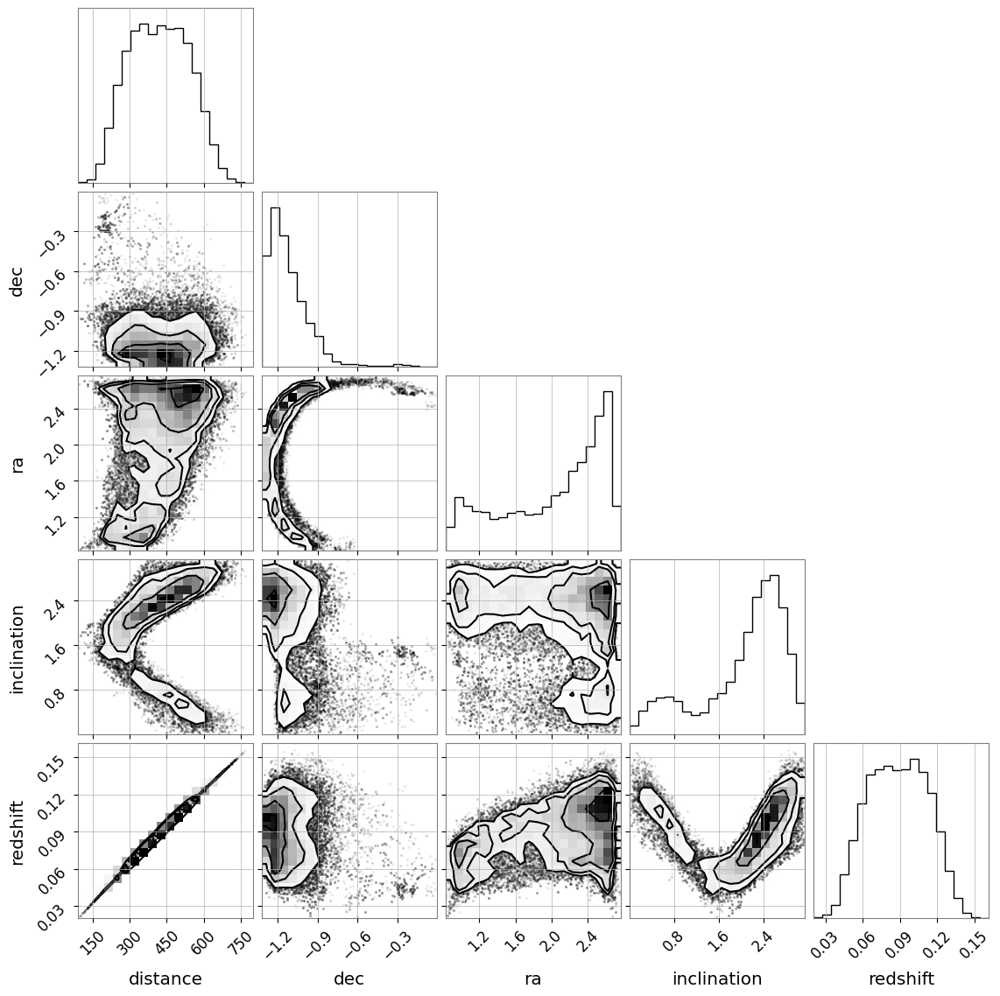

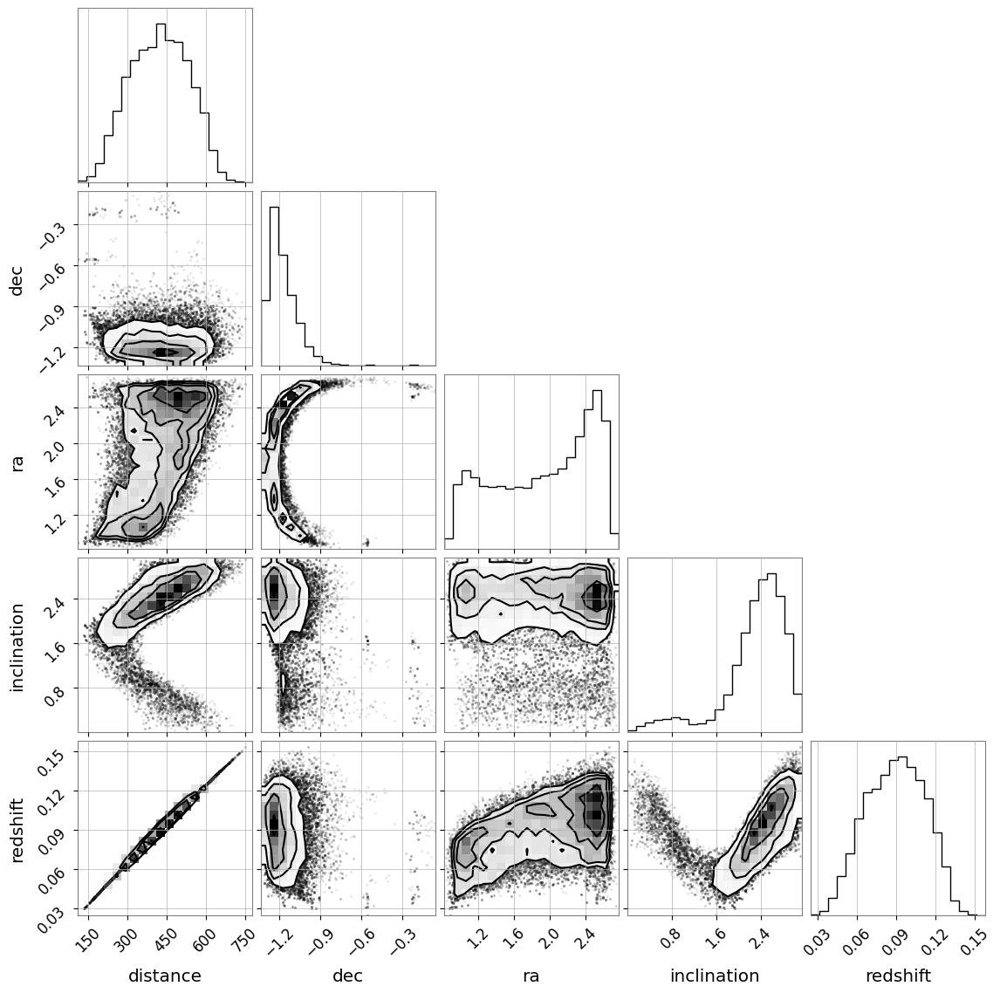

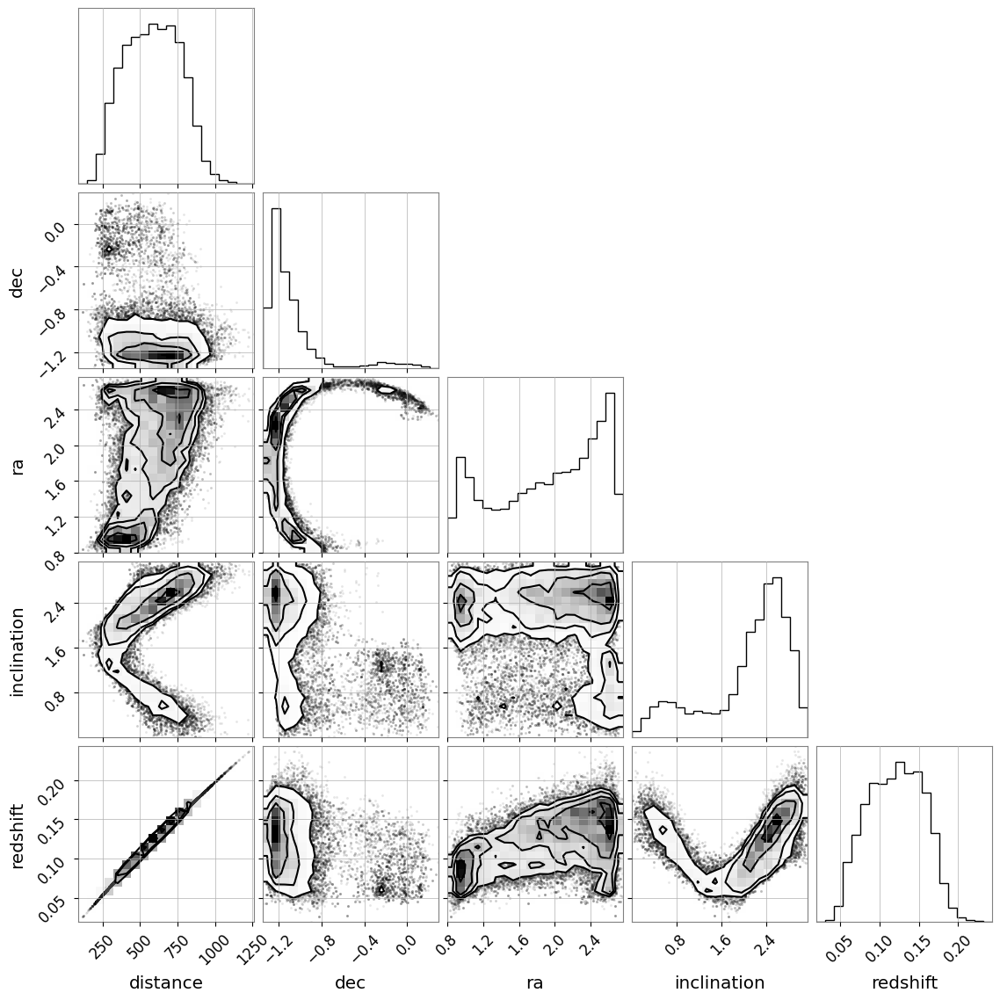

In [53]:
par_list = ['distance', 'dec', 'ra', 'inclination', 'redshift']
corner.corner(samples['GW150914_095045']['dchi3'][par_list], labels=par_list);

par_list = ['distance', 'dec', 'ra', 'inclination', 'redshift']
corner.corner(samples['GW150914_095045']['cpsi3'][par_list], labels=par_list);

par_list = ['distance', 'dec', 'ra', 'inclination', 'redshift']
corner.corner(samples['GW150914_095045']['cpsi4'][par_list], labels=par_list);

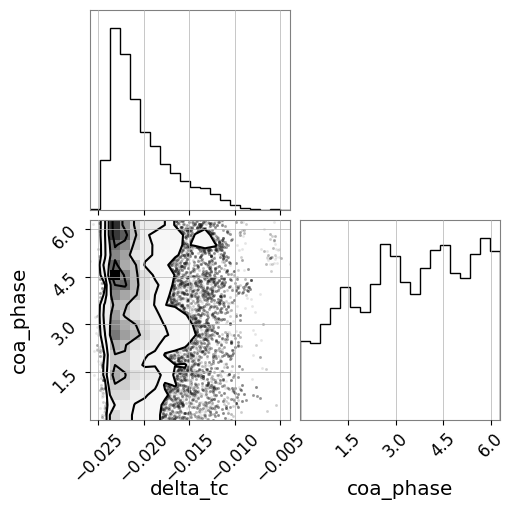

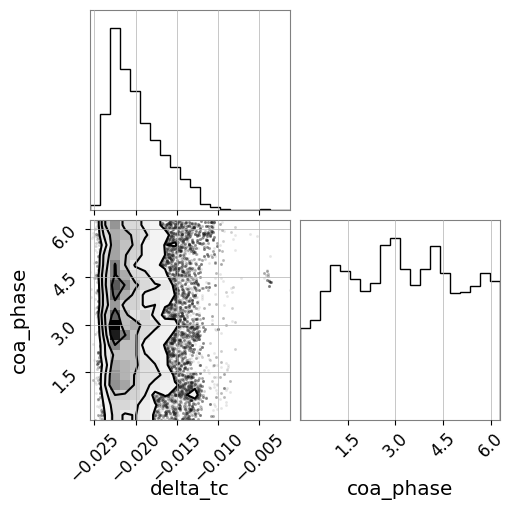

In [55]:

par_list = ['delta_tc', "coa_phase"]
corner.corner(samples['GW150914_095045']['dchi3'][par_list], labels=par_list);

par_list = ['delta_tc', "coa_phase"]
corner.corner(samples['GW150914_095045']['cpsi3'][par_list], labels=par_list);

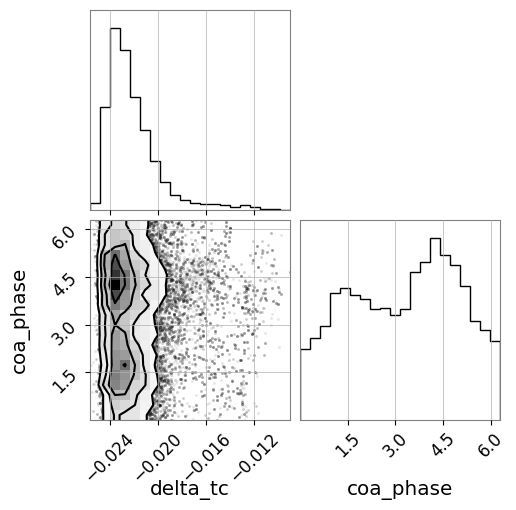

In [62]:
par_list = ['delta_tc', "coa_phase"]
corner.corner(samples['GW150914']['GR'][par_list], labels=par_list);

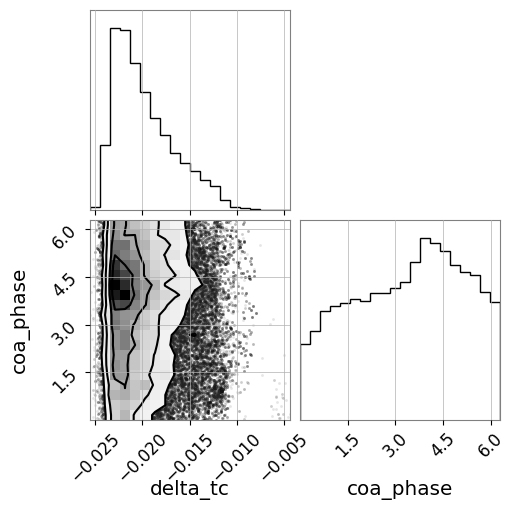

In [72]:
par_list = ['delta_tc', "coa_phase"]
corner.corner(samples['GW150914']['cpsi3'][par_list], labels=par_list);

## NON-GR Parameters

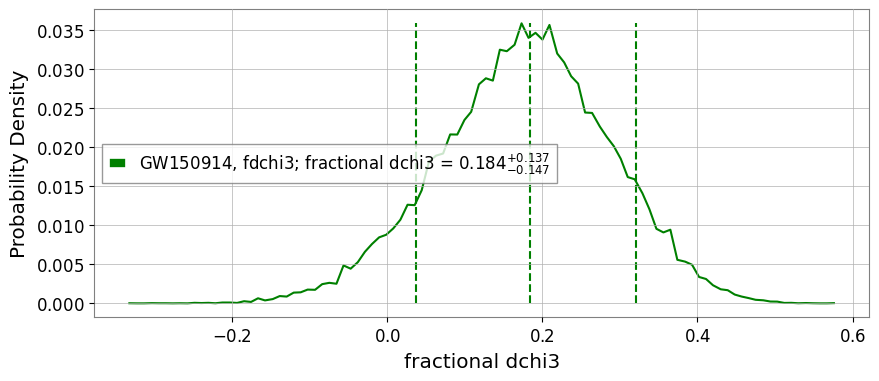

In [33]:
parameter_latex = 'fractional dchi3'
parameter_name_official = 'dchi3'
parameter_name_pycbc = 'dchi3'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['fdchi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)

pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()

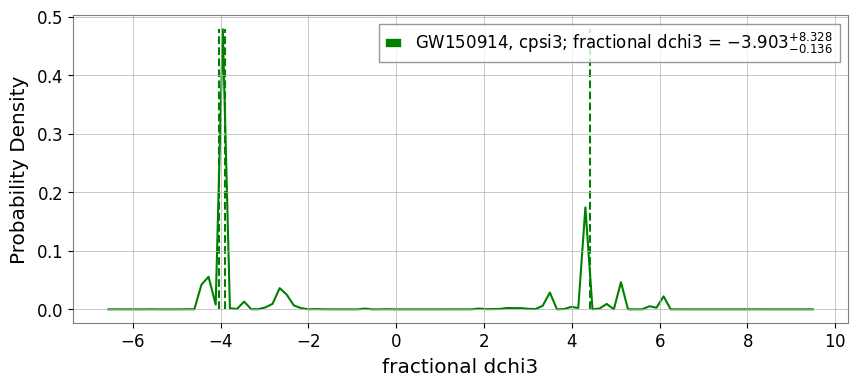

In [47]:
parameter_latex = 'fractional dchi3'
parameter_name_official = 'dchi3'
parameter_name_pycbc = 'dchi3'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['cpsi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)

pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()

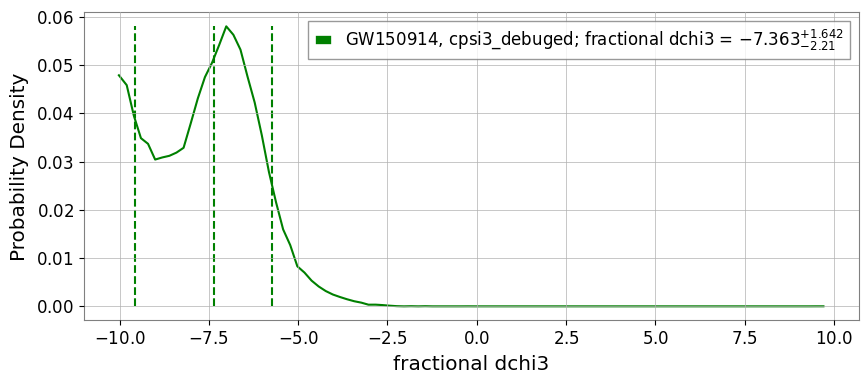

In [136]:
parameter_latex = 'fractional dchi3'
parameter_name_official = 'dchi3'
parameter_name_pycbc = 'dchi3'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['cpsi3_debuged'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3_debuged'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)

pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()

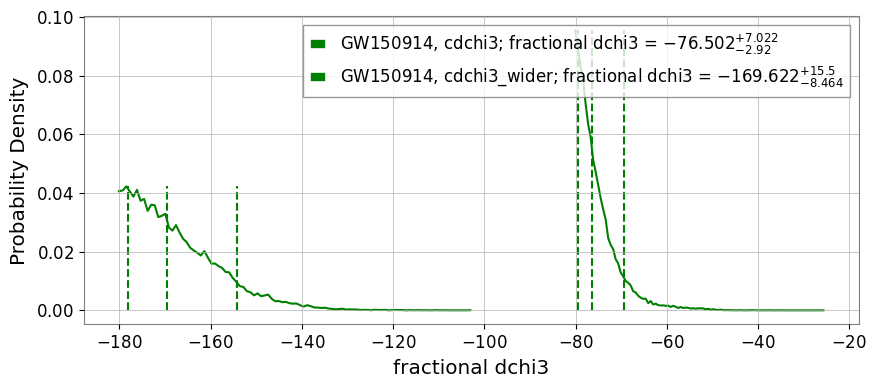

In [21]:
parameter_latex = 'fractional dchi3'
parameter_name_official = 'dchi3'
parameter_name_pycbc = 'dchi3'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['cdchi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cdchi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)
plot_parameter(samples['GW150914']['cdchi3_wider'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cdchi3_wider'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)

pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()

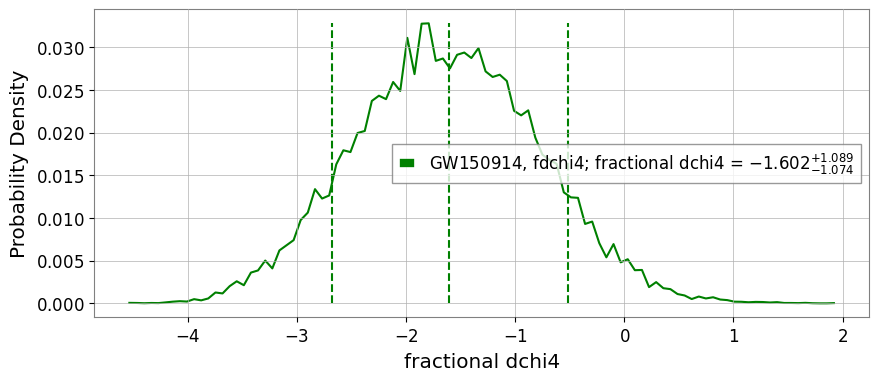

In [67]:
parameter_latex = 'fractional dchi4'
parameter_name_official = 'dchi4'
parameter_name_pycbc = 'dchi4'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['fdchi4'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi4'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)

pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()

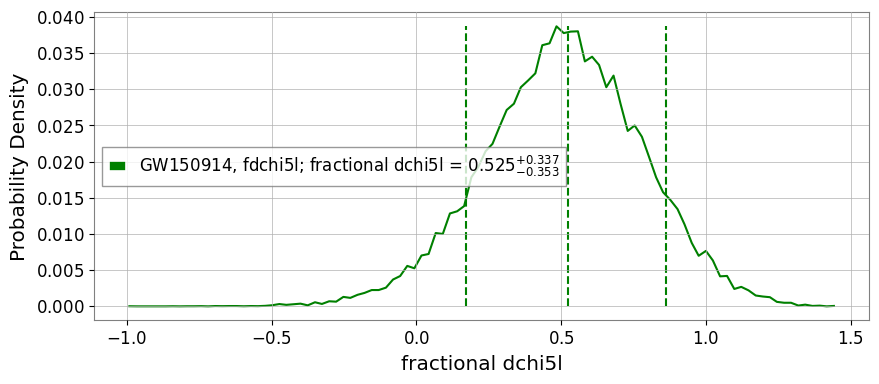

In [66]:
parameter_latex = 'fractional dchi5l'
parameter_name_official = 'dchi5l'
parameter_name_pycbc = 'dchi5l'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['fdchi5l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi5l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)

pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()

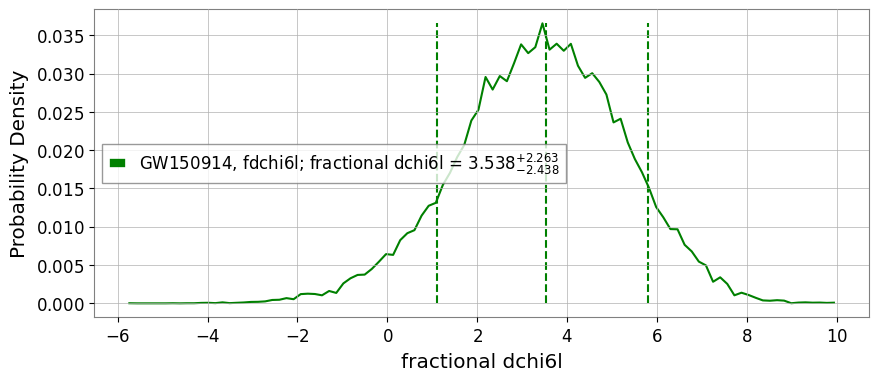

In [65]:
parameter_latex = 'fractional dchi6l'
parameter_name_official = 'dchi6l'
parameter_name_pycbc = 'dchi6l'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['fdchi6l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi6l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)

pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()

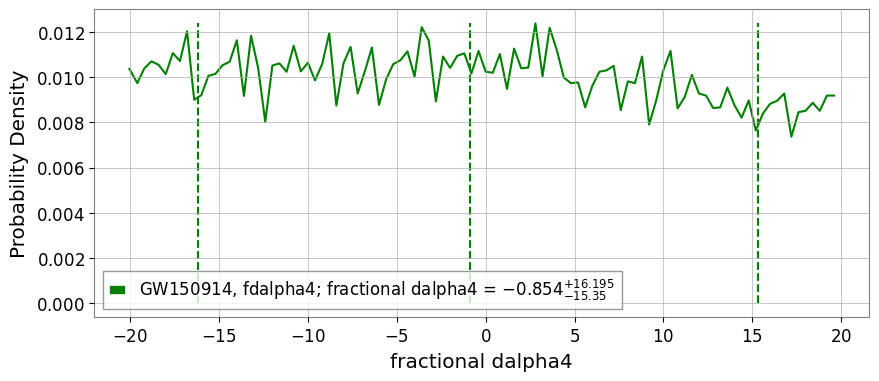

In [69]:
parameter_latex = 'fractional dalpha4'
parameter_name_official = 'dalpha4'
parameter_name_pycbc = 'dalpha4'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['fdalpha4'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdalpha4'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)

pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()

## Mass Parameters

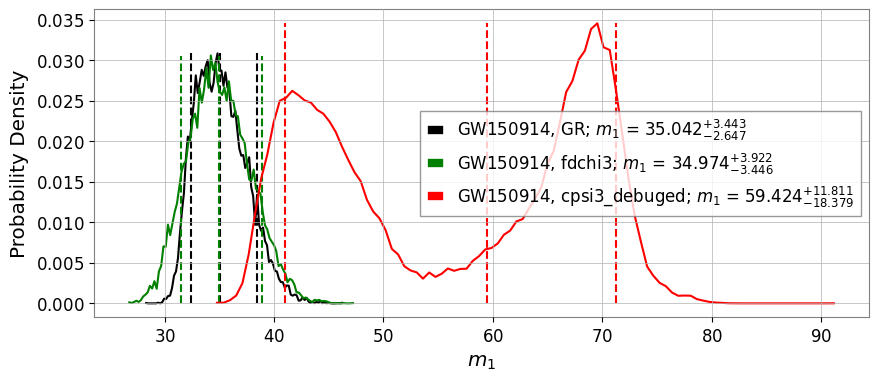

In [137]:
parameter_latex = '$m_1$'
parameter_name_official = 'mass_1'
parameter_name_pycbc = 'mass1'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['GR'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['GR'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='black', vlines_colors='black', if_plot_vlines=True)
plot_parameter(samples['GW150914']['fdchi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)

# plot_parameter(samples['GW150914']['fdchi4'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi4'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='purple', vlines_colors='purple', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi5l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi5l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi6l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi6l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)

# plot_parameter(samples['GW150914']['cpsi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='red', vlines_colors='red', if_plot_vlines=True)
plot_parameter(samples['GW150914']['cpsi3_debuged'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3_debuged'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='red', vlines_colors='red', if_plot_vlines=True)


pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()

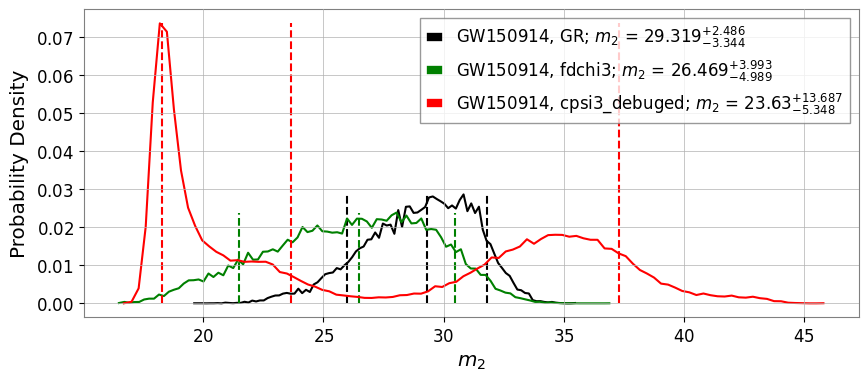

In [138]:
parameter_latex = '$m_2$'
parameter_name_official = 'mass_2'
parameter_name_pycbc = 'mass2'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['GR'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['GR'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='black', vlines_colors='black', if_plot_vlines=True)
plot_parameter(samples['GW150914']['fdchi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='red', vlines_colors='red', if_plot_vlines=True)
plot_parameter(samples['GW150914']['cpsi3_debuged'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3_debuged'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='red', vlines_colors='red', if_plot_vlines=True)

# plot_parameter(samples['GW150914']['fdchi4'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi4'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='purple', vlines_colors='purple', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi5l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi5l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi6l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi6l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)

# plot_parameter(samples['GW150914']['cpsi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)


pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()

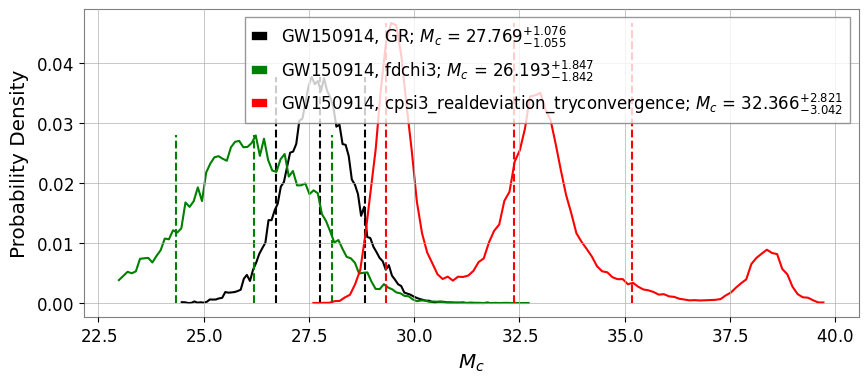

In [101]:
parameter_latex = '$M_c$'
parameter_name_official = 'Mchirp'
parameter_name_pycbc = 'Mchirp'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['GR'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['GR'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='black', vlines_colors='black', if_plot_vlines=True)
plot_parameter(samples['GW150914']['fdchi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['cpsi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
plot_parameter(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='red', vlines_colors='red', if_plot_vlines=True)

# plot_parameter(samples['GW150914']['fdchi4'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi4'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='purple', vlines_colors='purple', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi5l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi5l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi6l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi6l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)


pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()

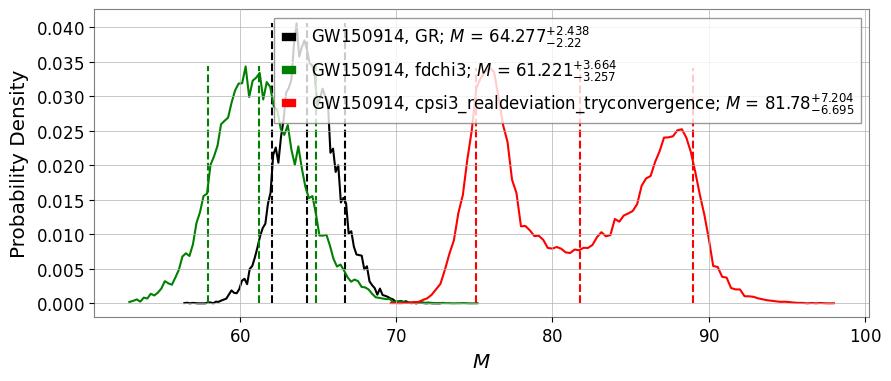

In [102]:
parameter_latex = '$M$'
parameter_name_official = 'Mtot'
parameter_name_pycbc = 'Mtot'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['GR'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['GR'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='black', vlines_colors='black', if_plot_vlines=True)
plot_parameter(samples['GW150914']['fdchi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['cpsi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
plot_parameter(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='red', vlines_colors='red', if_plot_vlines=True)

# plot_parameter(samples['GW150914']['fdchi4'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi4'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='purple', vlines_colors='purple', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi5l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi5l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi6l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi6l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)


pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()

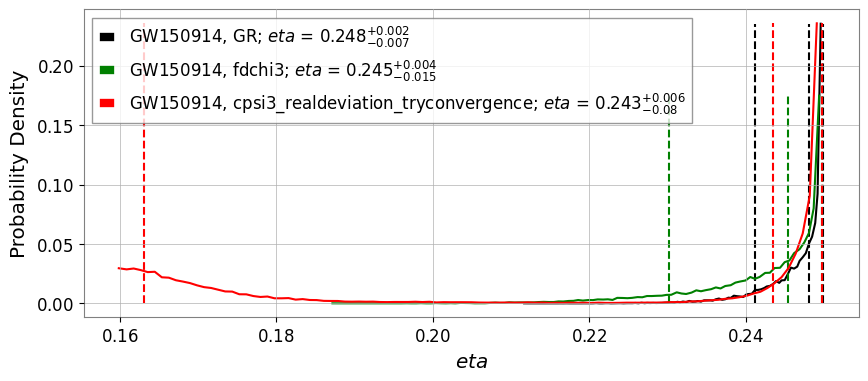

In [103]:
parameter_latex = '$eta$'
parameter_name_official = 'eta'
parameter_name_pycbc = 'eta'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['GR'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['GR'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='black', vlines_colors='black', if_plot_vlines=True)
plot_parameter(samples['GW150914']['fdchi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['cpsi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
plot_parameter(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='red', vlines_colors='red', if_plot_vlines=True)

# plot_parameter(samples['GW150914']['fdchi4'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi4'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='purple', vlines_colors='purple', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi5l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi5l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi6l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi6l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)


pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()

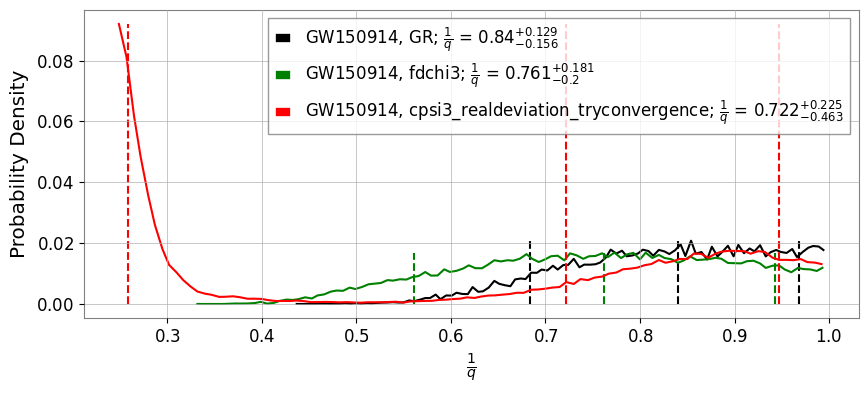

In [104]:
parameter_latex = '$\\frac{{1}}{{q}}$'
parameter_name_official = 'invq'
parameter_name_pycbc = 'invq'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['GR'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['GR'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='black', vlines_colors='black', if_plot_vlines=True)
plot_parameter(samples['GW150914']['fdchi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['cpsi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
plot_parameter(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='red', vlines_colors='red', if_plot_vlines=True)

# plot_parameter(samples['GW150914']['fdchi4'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi4'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='purple', vlines_colors='purple', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi5l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi5l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi6l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi6l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)


pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()

## Spin Parameters

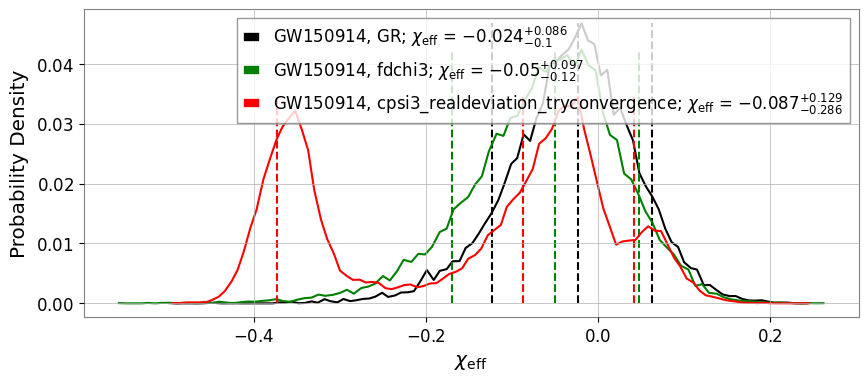

In [105]:
parameter_latex = '$\\chi_\\text{eff}$'
parameter_name_official = 'chi_eff'
parameter_name_pycbc = 'chi_eff'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['GR'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['GR'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='black', vlines_colors='black', if_plot_vlines=True)
plot_parameter(samples['GW150914']['fdchi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['cpsi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
plot_parameter(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='red', vlines_colors='red', if_plot_vlines=True)

# plot_parameter(samples['GW150914']['fdchi4'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi4'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='purple', vlines_colors='purple', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi5l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi5l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi6l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi6l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)


pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()

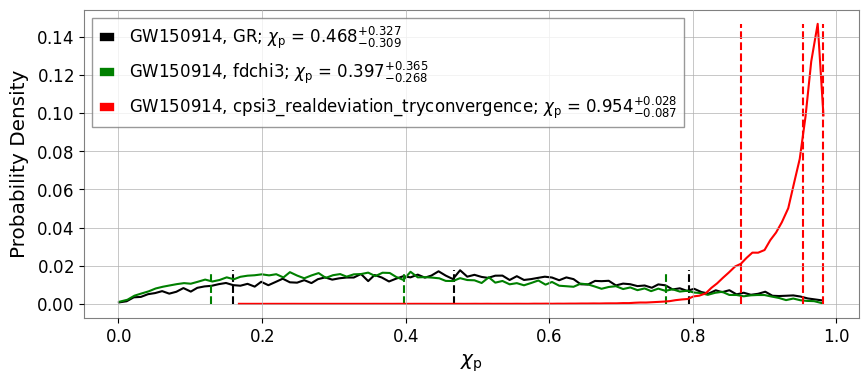

In [106]:
parameter_latex = '$\\chi_\\text{p}$'
parameter_name_official = 'chi_p'
parameter_name_pycbc = 'chi_p'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['GR'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['GR'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='black', vlines_colors='black', if_plot_vlines=True)
plot_parameter(samples['GW150914']['fdchi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['cpsi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
plot_parameter(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='red', vlines_colors='red', if_plot_vlines=True)

# plot_parameter(samples['GW150914']['fdchi4'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi4'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='purple', vlines_colors='purple', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi5l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi5l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi6l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi6l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)


pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()

## Location Parameters

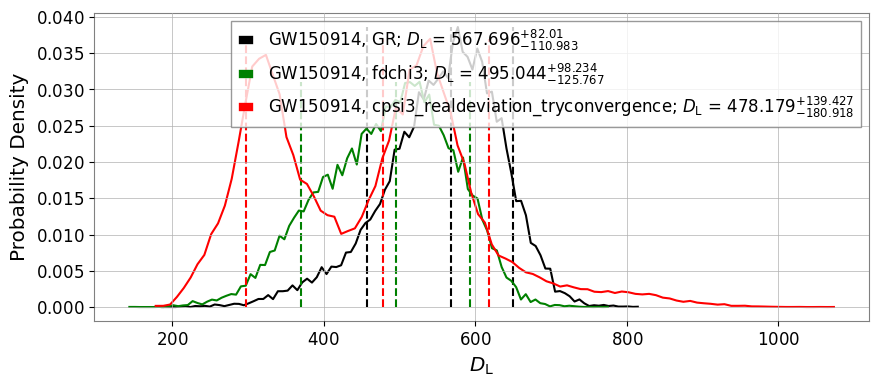

In [107]:
parameter_latex = '$D_\\text{L}$'
parameter_name_official = 'distance'
parameter_name_pycbc = 'distance'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['GR'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['GR'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='black', vlines_colors='black', if_plot_vlines=True)
plot_parameter(samples['GW150914']['fdchi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['cpsi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
plot_parameter(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='red', vlines_colors='red', if_plot_vlines=True)

# plot_parameter(samples['GW150914']['fdchi4'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi4'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='purple', vlines_colors='purple', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi5l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi5l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi6l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi6l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)


pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()

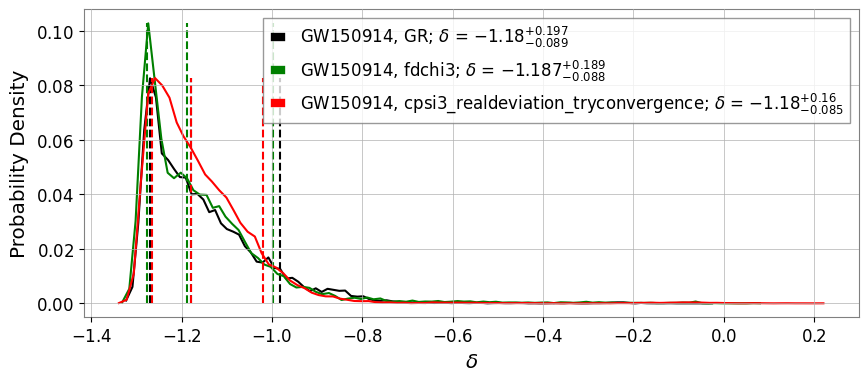

In [108]:
parameter_latex = '$\\delta$'
parameter_name_official = 'dec'
parameter_name_pycbc = 'dec'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['GR'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['GR'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='black', vlines_colors='black', if_plot_vlines=True)
plot_parameter(samples['GW150914']['fdchi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['cpsi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
plot_parameter(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='red', vlines_colors='red', if_plot_vlines=True)

# plot_parameter(samples['GW150914']['fdchi4'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi4'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='purple', vlines_colors='purple', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi5l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi5l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi6l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi6l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)


pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()

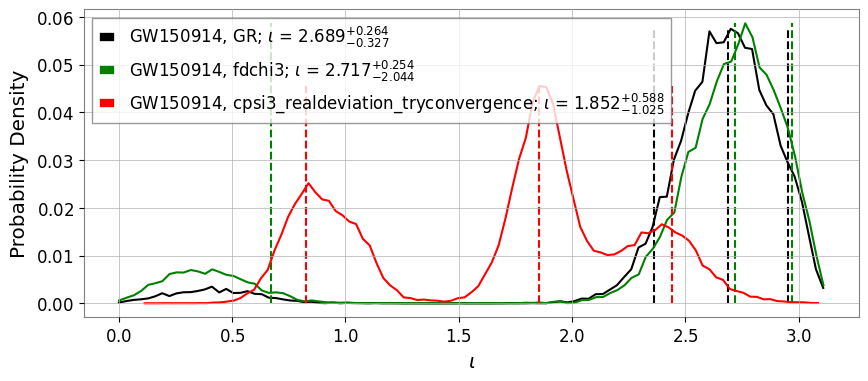

In [109]:
parameter_latex = '$\\iota$'
parameter_name_official = 'inclination'
parameter_name_pycbc = 'inclination'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['GR'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['GR'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='black', vlines_colors='black', if_plot_vlines=True)
plot_parameter(samples['GW150914']['fdchi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['cpsi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
plot_parameter(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='red', vlines_colors='red', if_plot_vlines=True)

# plot_parameter(samples['GW150914']['fdchi4'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi4'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='purple', vlines_colors='purple', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi5l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi5l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi6l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi6l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)


pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()

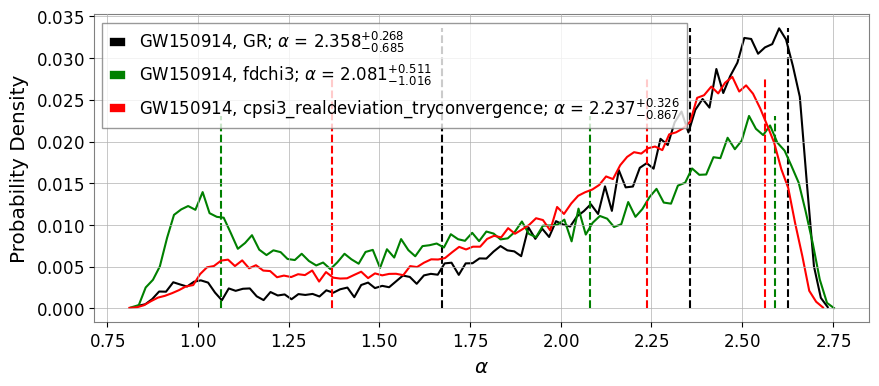

In [95]:
parameter_latex = '$\\alpha$'
parameter_name_official = 'ra'
parameter_name_pycbc = 'ra'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['GR'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['GR'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='black', vlines_colors='black', if_plot_vlines=True)
plot_parameter(samples['GW150914']['fdchi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['cpsi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
plot_parameter(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='red', vlines_colors='red', if_plot_vlines=True)

# plot_parameter(samples['GW150914']['fdchi4'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi4'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='purple', vlines_colors='purple', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi5l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi5l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi6l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi6l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)


pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()

## Other Parameters

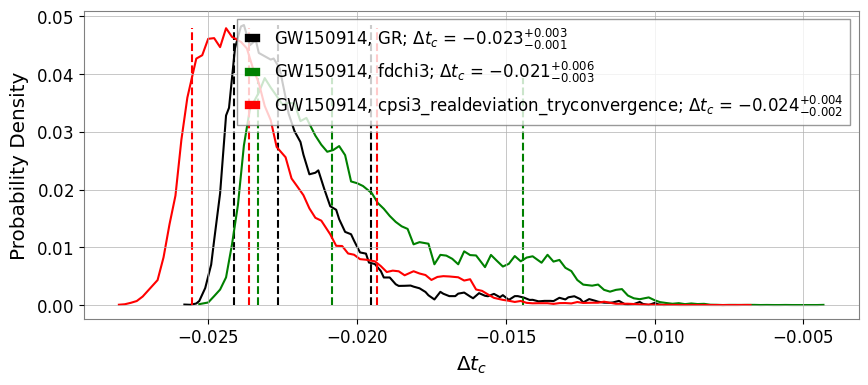

In [96]:
parameter_latex = '$\\Delta t_c$'
parameter_name_official = 'delta_tc'
parameter_name_pycbc = 'delta_tc'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['GR'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['GR'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='black', vlines_colors='black', if_plot_vlines=True)
plot_parameter(samples['GW150914']['fdchi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['cpsi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
plot_parameter(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='red', vlines_colors='red', if_plot_vlines=True)

# plot_parameter(samples['GW150914']['fdchi4'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi4'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='purple', vlines_colors='purple', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi5l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi5l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi6l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi6l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)


pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()

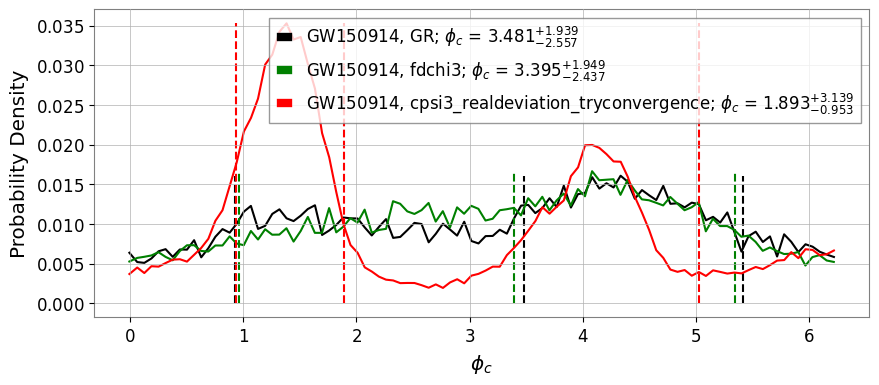

In [97]:
parameter_latex = '$\\phi_c$'
parameter_name_official = 'coa_phase'
parameter_name_pycbc = 'coa_phase'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['GR'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['GR'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='black', vlines_colors='black', if_plot_vlines=True)
plot_parameter(samples['GW150914']['fdchi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['cpsi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
plot_parameter(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='red', vlines_colors='red', if_plot_vlines=True)

# plot_parameter(samples['GW150914']['fdchi4'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi4'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='purple', vlines_colors='purple', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi5l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi5l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi6l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi6l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)


pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()

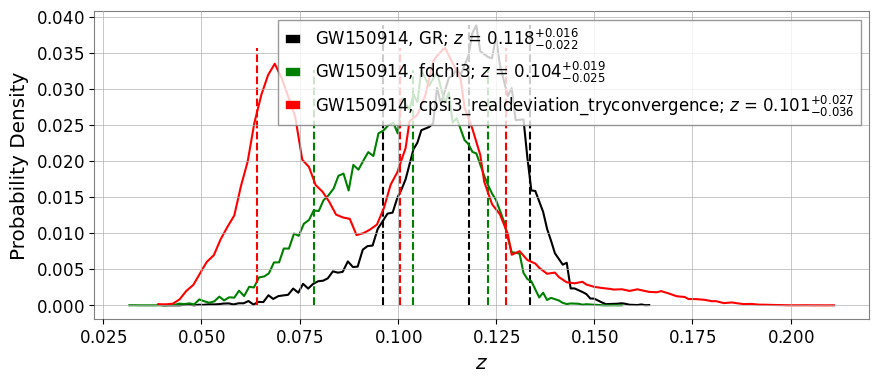

In [98]:
parameter_latex = '$z$'
parameter_name_official = 'redshift'
parameter_name_pycbc = 'redshift'

pp.figure(figsize=(10, 4))
plot_parameter(samples['GW150914']['GR'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['GR'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='black', vlines_colors='black', if_plot_vlines=True)
plot_parameter(samples['GW150914']['fdchi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='green', vlines_colors='green', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['cpsi3'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
plot_parameter(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['cpsi3_realdeviation_tryconvergence'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='red', vlines_colors='red', if_plot_vlines=True)

# plot_parameter(samples['GW150914']['fdchi4'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi4'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='purple', vlines_colors='purple', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi5l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi5l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)
# plot_parameter(samples['GW150914']['fdchi6l'], parameter_name_pycbc, label=get_label_str(samples['GW150914']['fdchi6l'], parameter_name_pycbc, parameter_latex), bins=100, boundary_color='blue', vlines_colors='blue', if_plot_vlines=True)


pp.xlabel(parameter_latex)
pp.ylabel('Probability Density')
pp.legend()